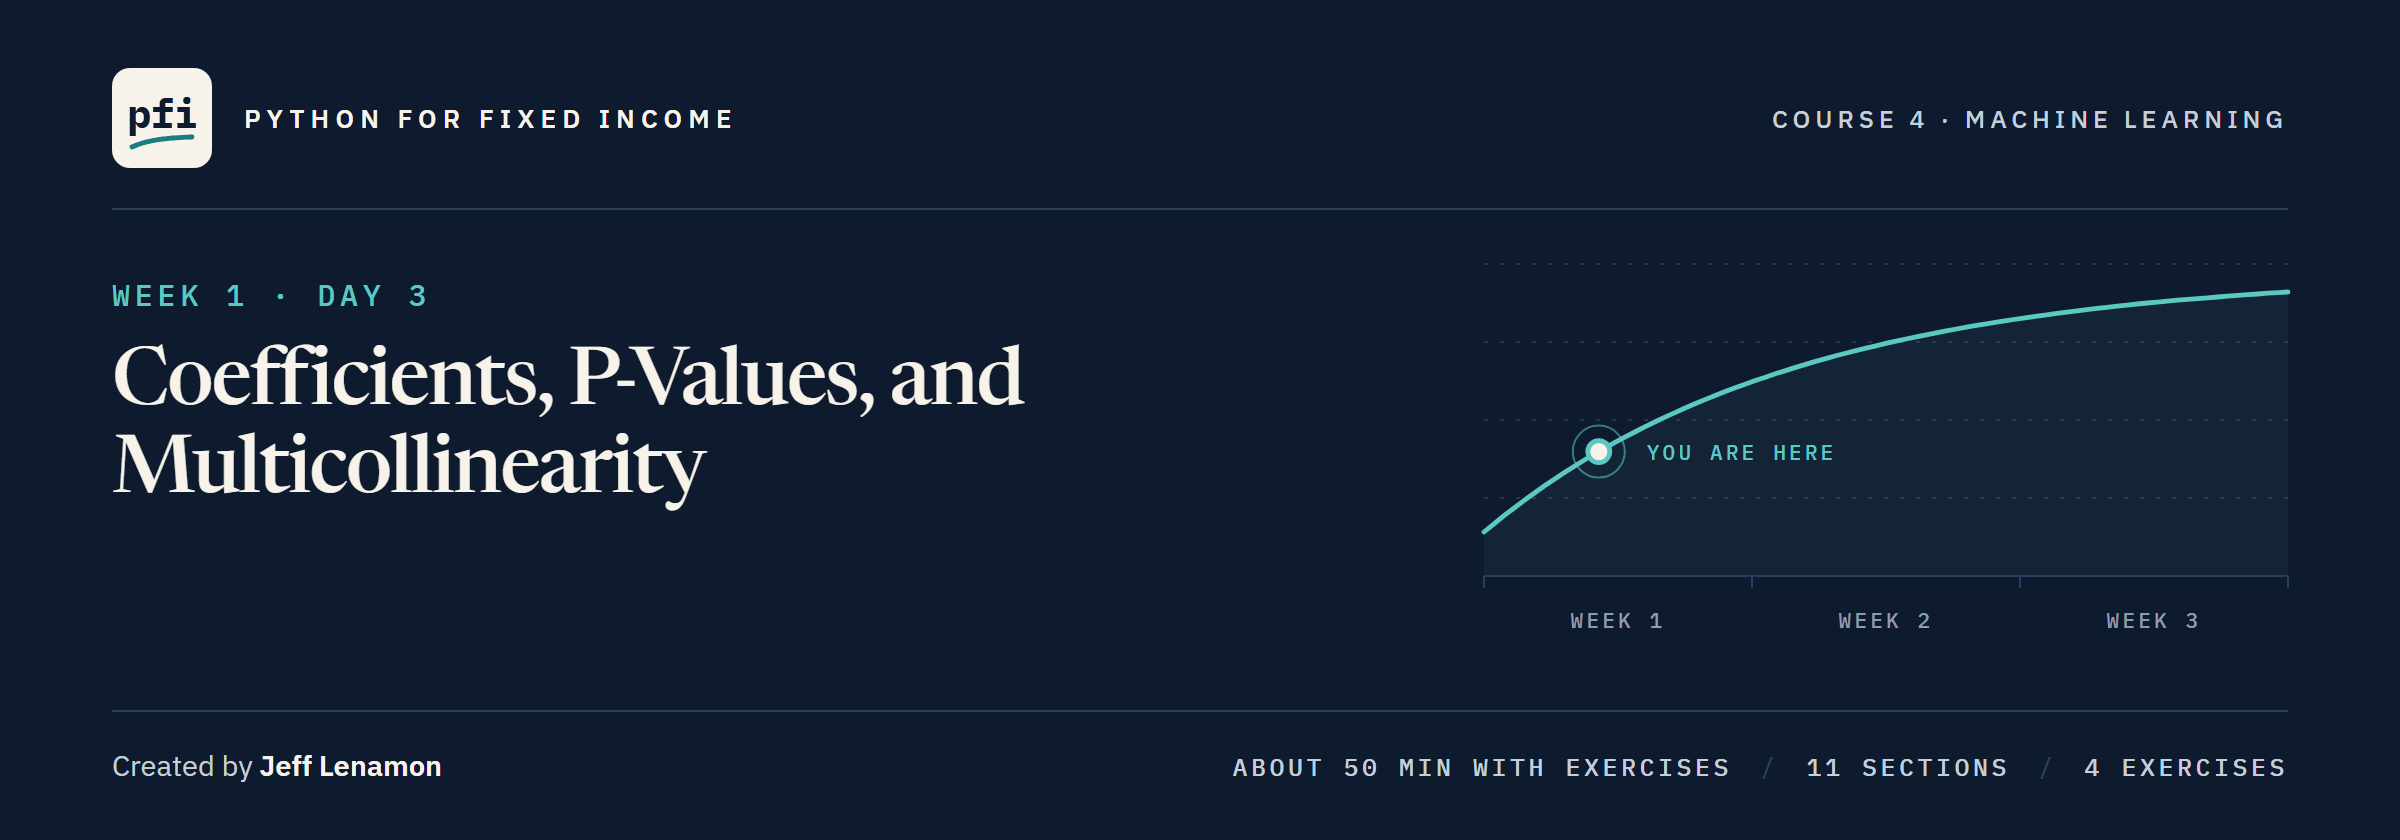

# Coefficients, P-Values, and Multicollinearity

Week 1, Day 3. Refit Day 2's model in statsmodels, read the error bar on every coefficient, and find the columns that bend those bars.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week1/day3/03_coefficients_p_values_and_multicollinearity.ipynb)

# Problem Statement

## Business Context

Day 2's model, 17 rating steps and duration, missed a typical unseen bond by 35.5 bp.
Before anyone quotes "a BB bond sits 164 bp over an A bond", the credit team asks how sure each coefficient is.
It also asks which columns earn a place: sector, and two more measures of a bond's length that the file carries.
The bonds and issuers are invented for this course.

## Objectives

Refit Day 2's model in statsmodels and read its coefficient table.
Test sector column by column and all together, find a near-copy feature and drop it, score the choices on the test bonds, and find where the error bars themselves go wrong.

## Data Dictionary

`benchmark.csv`, one row per bond:

1. `ticker`: the issuer's short code, shared by all of its bonds
2. `sector`: one of 10 industry sectors
3. `rating`: credit rating, AAA to CCC
4. `maturity` and `as_of_date`: the repayment date and the file's date
5. `oas`: option-adjusted spread, bp, **the target**
6. `duration`: modified duration, years
7. `spread_duration`: spread duration, years
8. `coupon` (Exercise 1) and `dts` (Exercise 4)

The file's other columns are not used today.

`ratings.csv` adds `score` and `grade` (Investment Grade or High Yield).

## Your Route Through Day 3

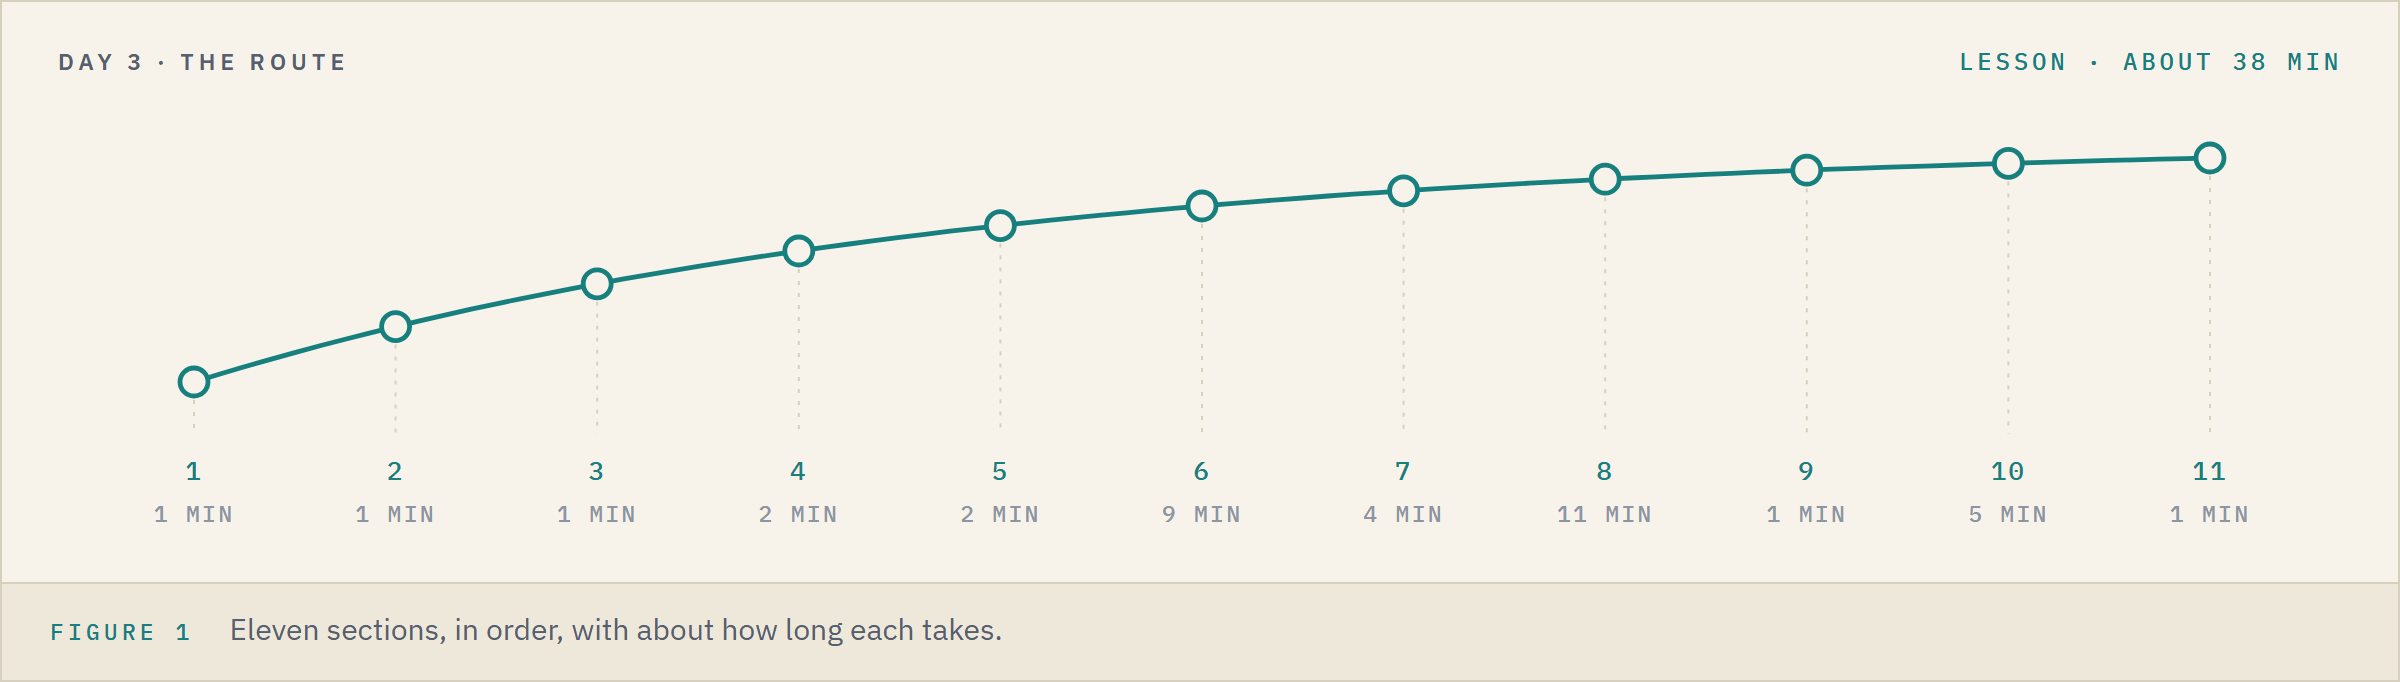

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">1</td><td align="left">Setting Up</td><td align="left">1 min</td></tr>
<tr><td align="left">2</td><td align="left">Loading the Data</td><td align="left">1 min</td></tr>
<tr><td align="left">3</td><td align="left">Data Overview</td><td align="left">1 min</td></tr>
<tr><td align="left">4</td><td align="left">Exploratory Data Analysis</td><td align="left">2 min</td></tr>
<tr><td align="left">5</td><td align="left">Data Preparation for Modeling</td><td align="left">2 min</td></tr>
<tr><td align="left">6</td><td align="left">Model Building</td><td align="left">9 min</td></tr>
<tr><td align="left">7</td><td align="left">Testing Sector</td><td align="left">4 min</td></tr>
<tr><td align="left">8</td><td align="left">Multicollinearity</td><td align="left">11 min</td></tr>
<tr><td align="left">9</td><td align="left">Model Performance Evaluation</td><td align="left">1 min</td></tr>
<tr><td align="left">10</td><td align="left">When the Error Bars Are Wrong</td><td align="left">5 min</td></tr>
<tr><td align="left">11</td><td align="left">Insights and Conclusion</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 38 minutes for the lesson, then about 12 for the four exercises.

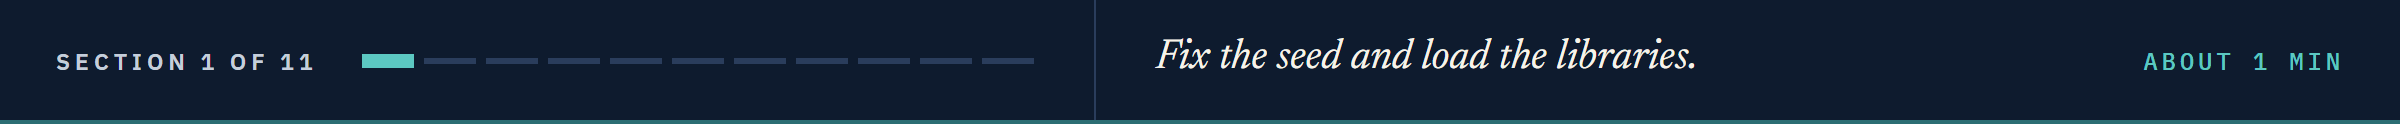

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and the t and normal curves from scipy
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# statsmodels: least squares with an error bar on every coefficient, and the variance inflation factor
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# to split the bonds, fit linear regressions, and score them
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# one look for every chart, and plain numbers with three decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.3f}".format)

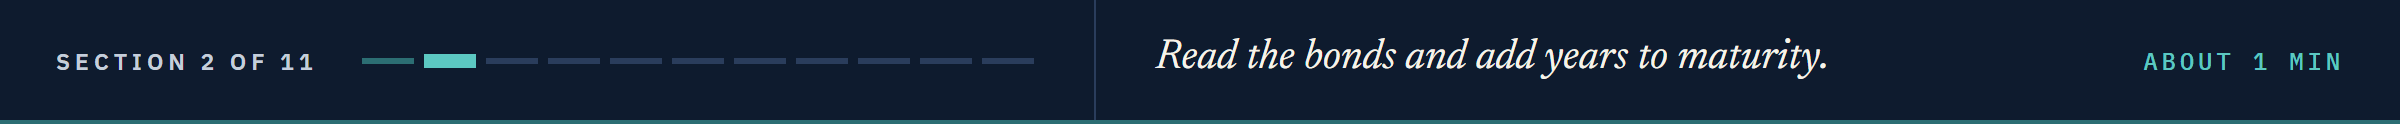

# Loading the Data

## Reading the Bonds and the Rating Scale

In [3]:
# the 821 bonds, and the table that turns each rating into a score and a grade
bonds = pd.read_csv(DATA + "benchmark.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
data = bonds.merge(ratings[["rating", "score", "grade"]], on="rating")

## Adding Years to Maturity

Course 1's line: the days from the file's date to maturity, divided by 365.25.

In [4]:
# each bond's years to maturity
data["years_to_maturity"] = (pd.to_datetime(data["maturity"]) - pd.to_datetime(data["as_of_date"])).dt.days / 365.25

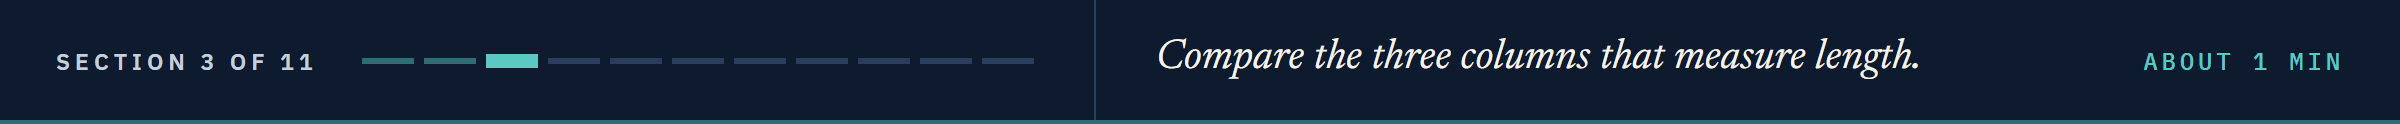

# Data Overview

## Three Measures of a Bond's Length

Q. How do duration, years to maturity and spread duration compare?

In [5]:
# the three length columns, summarised
data[["duration", "years_to_maturity", "spread_duration"]].describe()

,duration,years_to_maturity,spread_duration
count,821.000,821.000,821.000
mean,5.981,8.910,5.981
std,3.253,6.917,3.253
min,0.915,0.964,0.915
25%,3.434,4.030,3.434
50%,5.919,7.688,5.919
75%,7.743,10.713,7.743
max,16.042,29.897,16.042


Years to maturity runs from 0.96 to 29.9 years, duration from 0.92 to 16.0.

Duration and spread duration have the same summary, to the last digit.

**The file holds three columns that measure one bond's length, so we look at how closely they agree.**

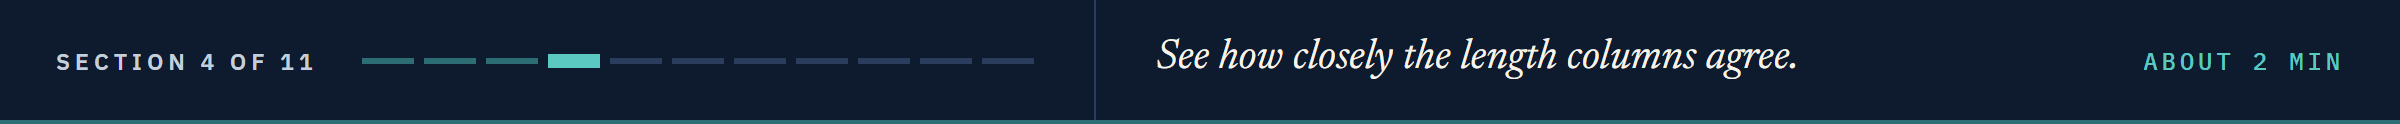

# Exploratory Data Analysis

## Bivariate Analysis

### Duration, Years to Maturity and Spread Duration

`corner=True` keeps only the lower half of a pair plot, so each pair appears once.

`plot_kws` passes settings to every scatter in the grid: here the dot size `s` and the see-through `alpha`.

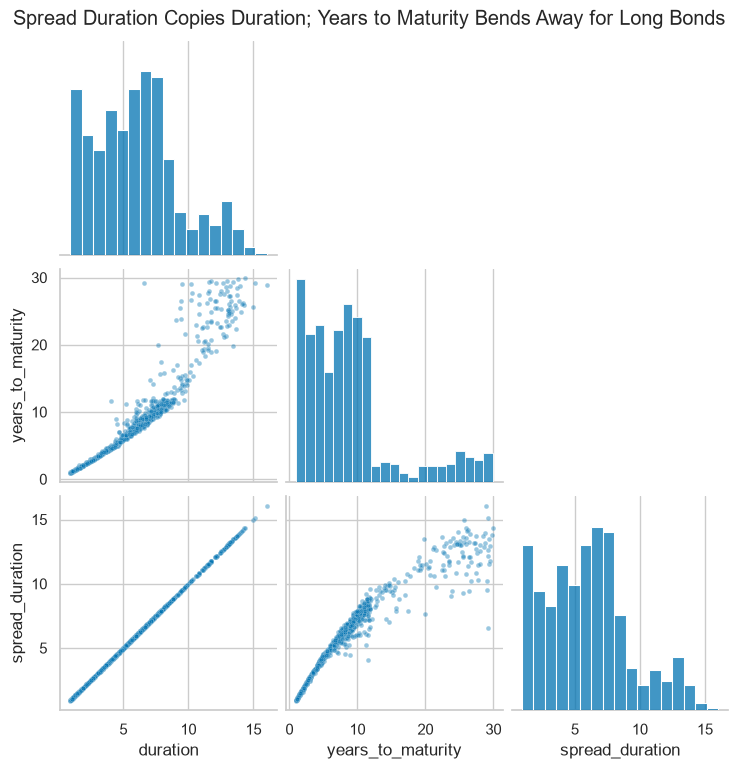

In [6]:
# every pair of the three length columns, each pair drawn once
grid = sns.pairplot(data[["duration", "years_to_maturity", "spread_duration"]], corner=True,
                    plot_kws={"s": 12, "alpha": 0.4})
grid.figure.suptitle("Spread Duration Copies Duration; Years to Maturity Bends Away for Long Bonds", y=1.02)
plt.show()

In [7]:
# is spread duration an exact copy of duration, and how closely do duration and years move together?
print("Spread duration equals duration on every bond:", (data["spread_duration"] == data["duration"]).all())
print("Correlation of duration and years to maturity:", round(data["duration"].corr(data["years_to_maturity"]), 3))

Spread duration equals duration on every bond: True
Correlation of duration and years to maturity: 0.942


Spread duration sits on duration exactly: in this file it is a copy.

Years and duration rise together, correlation 0.942, and bend apart for long bonds: a 30-year bond's duration stops near 16.

**Near-copies will matter once they sit in one model. First, we ask how sure a single coefficient is.**

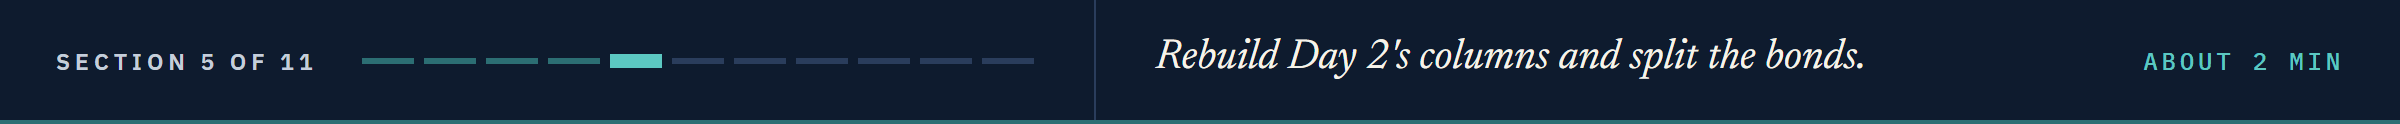

# Data Preparation for Modeling

## Rating and Sector Columns, Day 2's Way

In [8]:
# one column per rating in scale order, A left out as the reference level
rating_order = ratings["rating"]
rating_category = pd.Categorical(data["rating"], categories=rating_order)
rating_dummies = pd.get_dummies(rating_category, prefix="rating", dtype=float).drop(columns="rating_A")

# one column per sector, Consumer left out as the reference level
sector_dummies = pd.get_dummies(data["sector"], prefix="sector", dtype=float).drop(columns="sector_Consumer")

## Choosing the Features and Splitting

In [9]:
# every candidate column side by side, and the target: OAS in bp
lengths = data[["duration", "years_to_maturity", "spread_duration"]]
X = pd.concat([rating_dummies, sector_dummies, lengths], axis=1)
y = data["oas"]

# hold back a quarter of the bonds with the course seed
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)
print("Training bonds:", len(X_train), " Test bonds:", len(X_test))

Training bonds: 615  Test bonds: 206


In [10]:
# Day 2's chosen columns: the 17 rating steps from A, and duration
features_steps = list(rating_dummies.columns) + ["duration"]

**The same bonds, split and columns as Day 2's chosen model.**

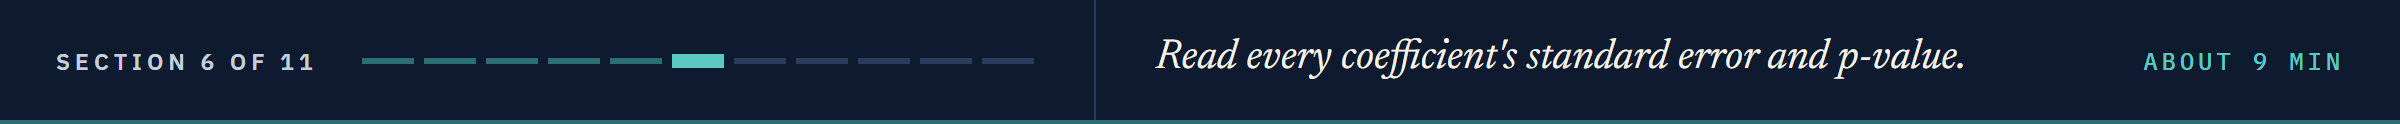

# Model Building

## `statsmodels`: The Same Model, With Error Bars

**statsmodels** fits the same least squares as scikit-learn, and also reports how sure it is of each coefficient.

It fits only the columns it is given, so `sm.add_constant` adds a column of 1.0s named `const`, whose coefficient is the intercept.

`sm.OLS(y, X).fit()` then fits ordinary least squares.

In [11]:
# add the column of 1.0s, then fit on the training bonds
ols_model = sm.OLS(y_train, sm.add_constant(X_train[features_steps])).fit()

## The Same Coefficients as `scikit-learn`

A statsmodels fit keeps its coefficients in `.params`, named by column.

In [12]:
# Day 2's scikit-learn model on the same columns and bonds
model_steps = LinearRegression()
model_steps.fit(X_train[features_steps], y_train)
sklearn_coefficients = pd.Series(model_steps.coef_, index=features_steps)

# the two libraries side by side
print("Same coefficients:", np.allclose(ols_model.params[features_steps], sklearn_coefficients))
print("BB step, statsmodels:", round(ols_model.params["rating_BB"], 2), " scikit-learn:", round(sklearn_coefficients["rating_BB"], 2))

Same coefficients: True
BB step, statsmodels: 164.41  scikit-learn: 164.41


One least squares, two libraries, the same 18 coefficients.

## The Coefficient Table

Q. How sure is the model of each coefficient?

`.summary2().tables[1]` is the model's coefficient table as a DataFrame.

In [13]:
# one row per coefficient, the intercept (const) first
table = ols_model.summary2().tables[1]
table

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,59.653,16.795,3.552,0.000,26.669,92.636
rating_AAA,-48.992,36.811,-1.331,0.184,-121.286,23.302
rating_AA+,-47.188,58.362,-0.809,0.419,-161.808,67.431
rating_AA,-38.617,57.870,-0.667,0.505,-152.270,75.037
rating_AA-,-29.421,32.437,-0.907,0.365,-93.125,34.284
rating_A+,-19.245,20.974,-0.918,0.359,-60.437,21.948
rating_A-,15.421,19.333,0.798,0.425,-22.549,53.391
rating_BBB+,25.150,21.036,1.196,0.232,-16.163,66.463
rating_BBB,47.975,22.683,2.115,0.035,3.427,92.523
rating_BBB-,78.009,19.461,4.008,0.000,39.788,116.230


In [14]:
# R-squared and adjusted R-squared on the training bonds, and the bonds left over after fitting 19 coefficients
print("R-squared:", round(ols_model.rsquared, 4), " Adjusted R-squared:", round(ols_model.rsquared_adj, 4))
print("Training bonds less coefficients:", int(ols_model.df_resid))

R-squared: 0.6727  Adjusted R-squared: 0.6628
Training bonds less coefficients: 596


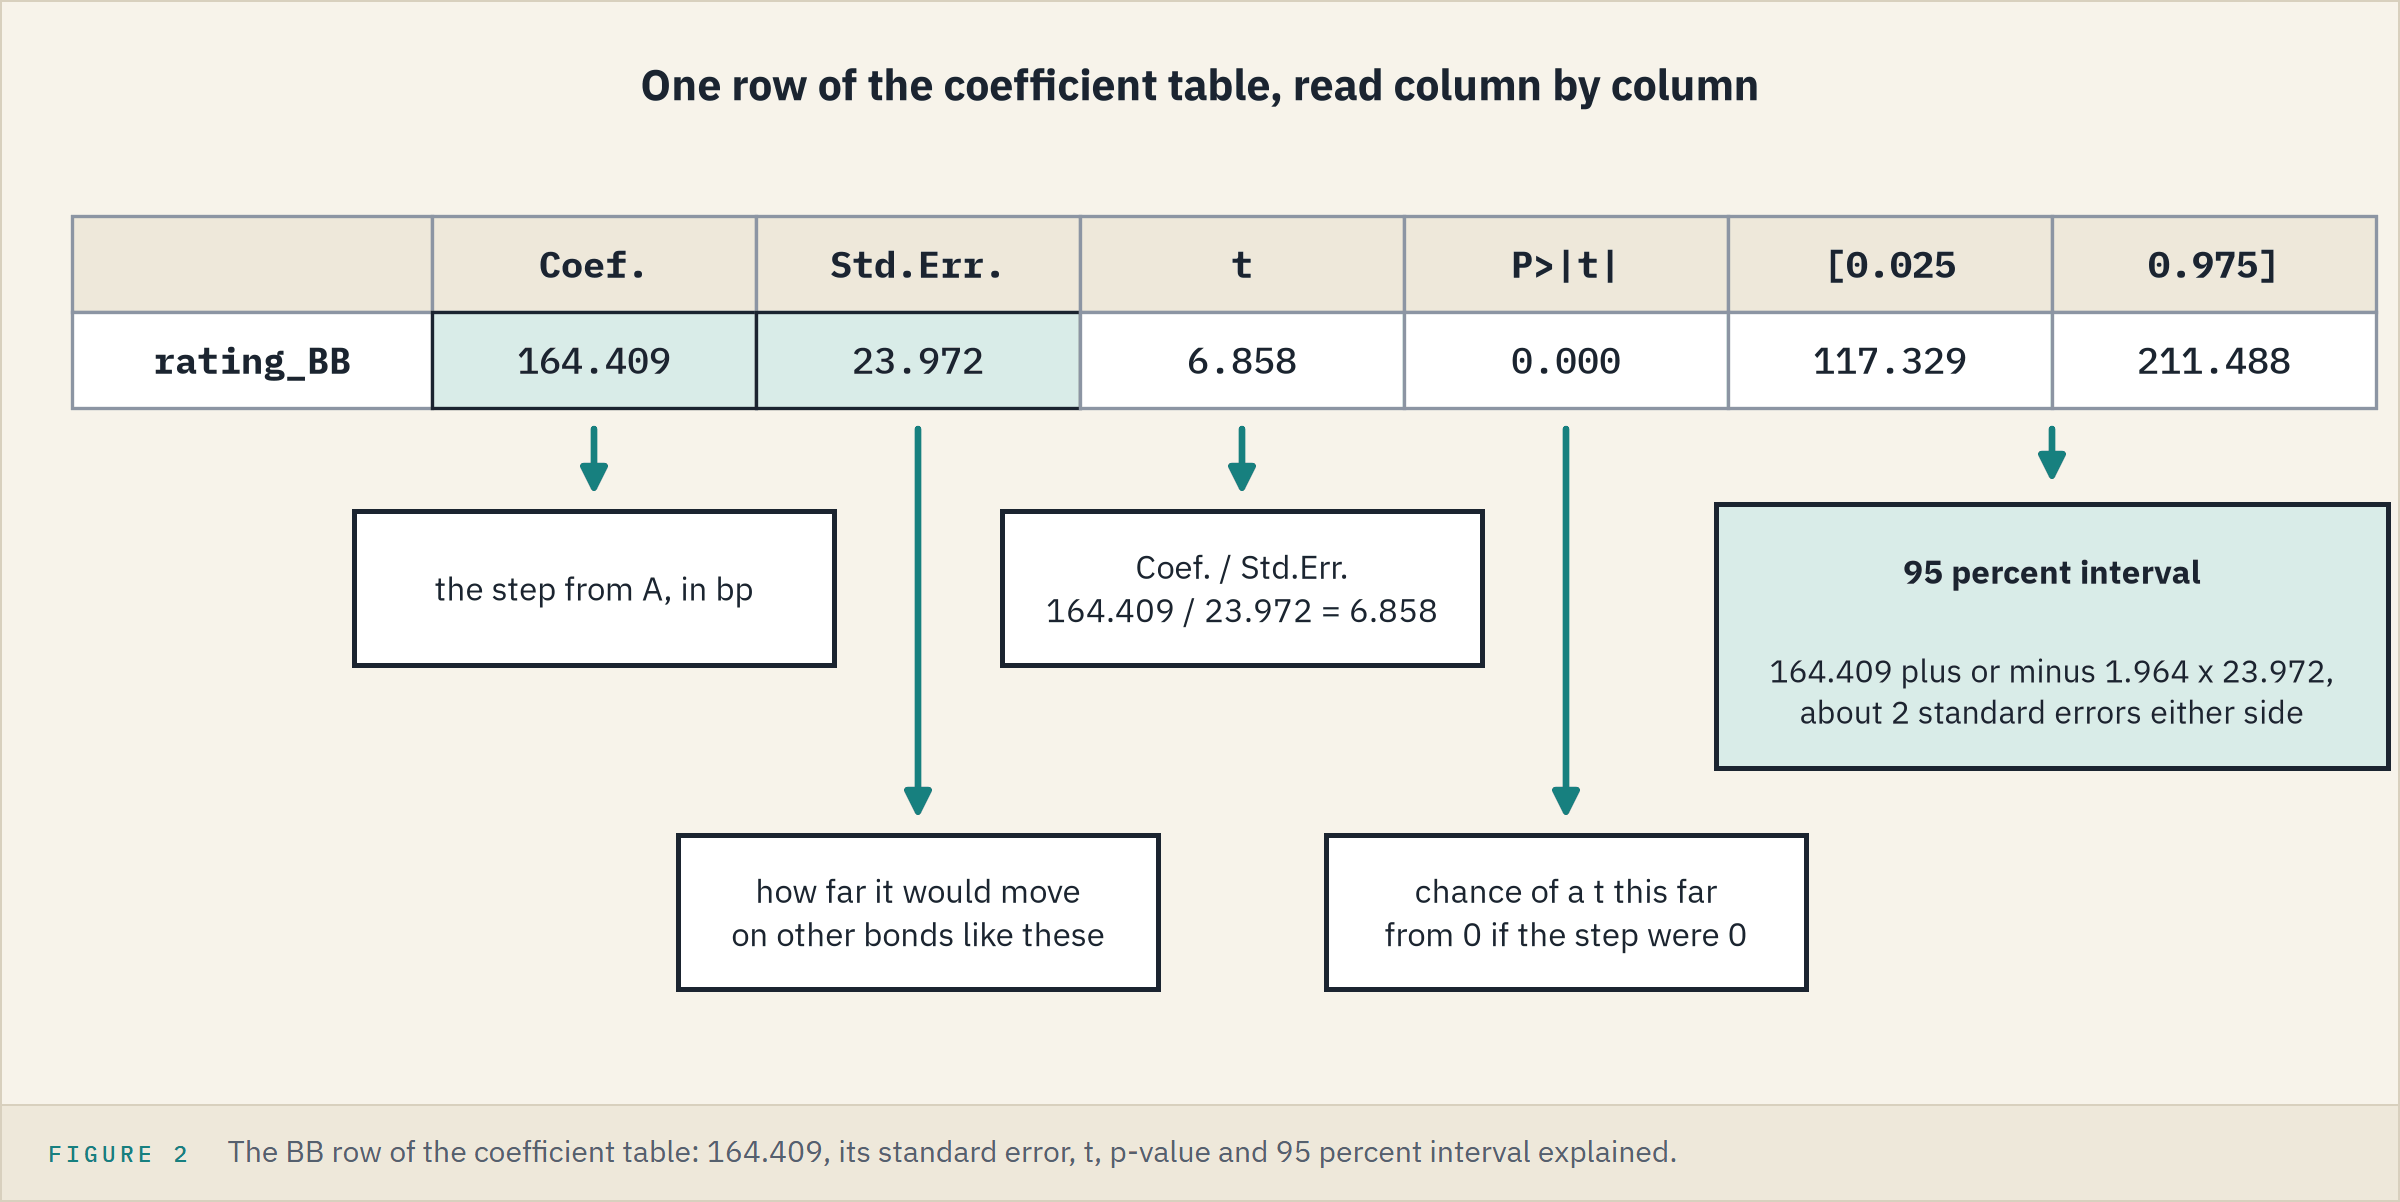

R-squared is Day 2's, 0.6727; the new part is the five columns beside each coefficient.

`Std.Err.`: the **standard error**, how far the coefficient would typically move if it were fitted on another set of bonds like these.

`t`: the coefficient divided by its standard error.

`P>|t|`: the **p-value**, below.

`[0.025` and `0.975]`: the **95 percent interval**, about two standard errors either side of the coefficient.

### Interpretation of the Coefficients

Holding duration fixed, a BB bond's fitted spread sits 164.4 bp above an A bond's, with a standard error of 24.0 bp and an interval of 117.3 to 211.5 bp.

A year of duration goes with 2.66 bp more, and its interval runs from -0.18 to 5.50 bp, so it could be nothing at all.

Say "goes with", never "causes": a coefficient describes these bonds, not what changing a bond would do.

### Interpretation of the P-Values

The **p-value** is how often a t this far from zero would turn up by chance if the true coefficient were zero and the model's assumptions held.

Below 0.05, a convention and nothing more, a coefficient is called **significant**.

Every step from BBB down to CCC is below 0.05; the seven steps from AAA to BBB+ sit at 0.184 to 0.505, and duration at 0.066.

A large p-value says these bonds cannot tell the coefficient from zero, not that it is zero.

A small one says nothing about cause or size.

## A P-Value as a Picture

The **t distribution** is the spread of t values that chance alone gives when the true coefficient is zero.

`stats.t.pdf` draws it for the 596 bonds left over, and `fill_between(..., where=)`, Course 2's shading, fills only where the condition holds.

In [15]:
# pick a column from the dropdown: its t on the t curve, both tails beyond it shaded
from ipywidgets import interact

def draw_p_value(name="rating_AAA"):
    t = table.loc[name, "t"]
    t_axis = np.linspace(-max(8, abs(t) + 2), max(8, abs(t) + 2), 801)
    curve = stats.t.pdf(t_axis, ols_model.df_resid)
    plt.figure(figsize=(10, 4))
    plt.plot(t_axis, curve, color="black")
    plt.fill_between(t_axis, curve, where=abs(t_axis) >= abs(t), color="tab:orange", alpha=0.7)
    plt.axvline(t, color="red")
    plt.xlabel("t (coefficient divided by its standard error)")
    plt.ylabel("Density")
    plt.title(name + ": t = " + str(round(t, 2)) + ", and the shaded tails hold p = " + str(round(table.loc[name, "P>|t|"], 3)))
    plt.show()

interact(draw_p_value, name=list(table.index));

interactive(children=(Dropdown(description='name', index=1, options=('const', 'rating_AAA', 'rating_AA+', 'rat…

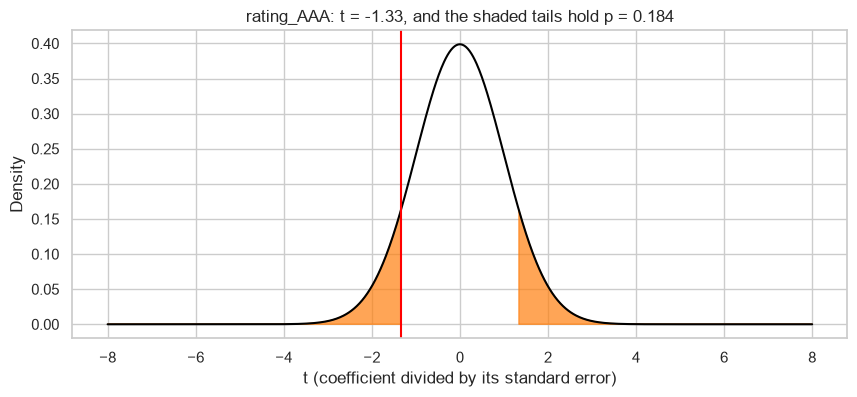

In [16]:
# the dropdown's starting choice, AAA, drawn as a still picture (dropdowns do not run on GitHub)
draw_p_value("rating_AAA")

AAA's t of -1.33 leaves 0.184 of the curve in the two tails: that share is its p-value.

Pick BB, t 6.86, and the shaded tails are too thin to see.

## How Sure Is Each Rating Step?

A **forest plot** draws one row per coefficient: a dot at the coefficient and a line across its 95 percent interval.

In [17]:
# a forest plot: gray where the interval crosses zero, blue where it stands clear of it
def draw_forest(rows, sizes):
    crosses = (rows["[0.025"] < 0) & (rows["0.975]"] > 0)
    colours = np.where(crosses, "gray", "tab:blue")
    position = np.arange(len(rows))
    plt.hlines(position, rows["[0.025"], rows["0.975]"], color=colours, linewidth=2.5)
    plt.scatter(rows["Coef."], position, s=sizes, color=colours, zorder=3)
    plt.yticks(position, rows.index)
    plt.axvline(0, color="black", linestyle="--")
    # two empty scatters: legend entries with no dots on the chart
    plt.scatter([], [], color="tab:blue", label="interval clear of zero")
    plt.scatter([], [], color="gray", label="interval crosses zero")

In [18]:
# the 17 steps and A at zero, CCC at the bottom, each named with its training bonds
steps = table.loc[rating_dummies.columns].copy()
steps.loc["rating_A"] = 0.0
steps = steps.loc["rating_" + rating_order].iloc[::-1]
counts = X_train[rating_dummies.columns].sum()
counts["rating_A"] = len(X_train) - counts.sum()
counts = counts[steps.index].astype(int)
steps.index = steps.index.str.replace("rating_", "") + "  (" + counts.astype(str).values + " bonds)"

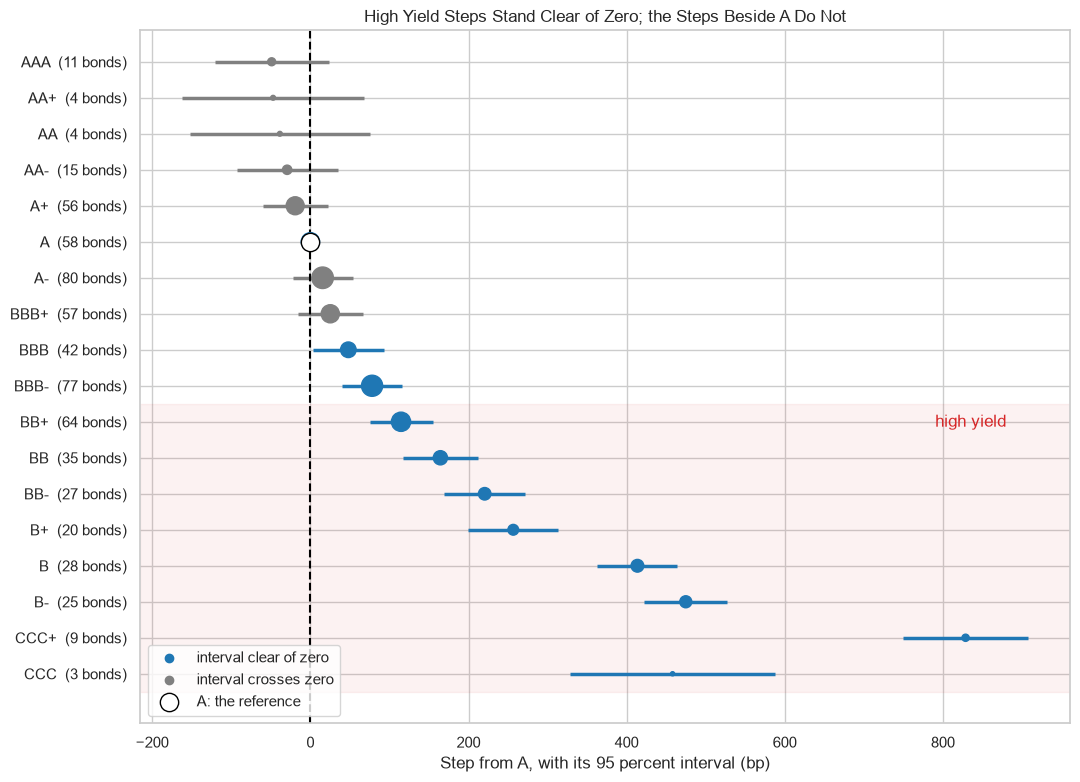

In [19]:
# the showpiece: every rating step with its interval, dot size by training bonds, high yield shaded
plt.figure(figsize=(12, 9))
plt.axhspan(-0.5, 7.5, color="tab:red", alpha=0.06)
draw_forest(steps, counts.values * 3)
# A, the reference, as a hollow dot at zero: white inside, a black ring
a_row = list(counts.index).index("rating_A")
plt.scatter(0, a_row, s=counts["rating_A"] * 3, facecolor="white", edgecolor="black", zorder=4, label="A: the reference")
plt.text(880, 7.2, "high yield", color="tab:red", ha="right", va="top")
plt.xlabel("Step from A, with its 95 percent interval (bp)")
plt.title("High Yield Steps Stand Clear of Zero; the Steps Beside A Do Not")
plt.legend(loc="lower left")
plt.show()

Few bonds make a wide line: AA+ runs from -161.8 to 67.4 bp on 4 bonds, and CCC from 327.9 to 588.2 bp on 3.

BBB-, on 77 bonds, runs from 39.8 to 116.2 bp.

Every line from AAA to BBB+ crosses zero: in bp, these bonds cannot tell those steps from A.

**Few bonds make a wide interval. Next, we look at a column with nothing in it.**

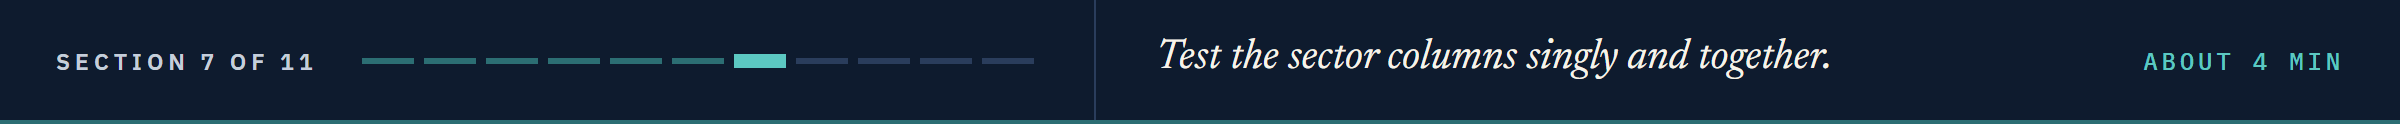

# Testing Sector

## Adding Sector

Day 2's nine sector columns made the test MAE slightly worse.

Now each one gets an interval.

In [20]:
# Day 2's columns plus the nine sector columns
features_sector = features_steps + list(sector_dummies.columns)
sector_model = sm.OLS(y_train, sm.add_constant(X_train[features_sector])).fit()
sector_table = sector_model.summary2().tables[1].loc[sector_dummies.columns]
sector_table

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
sector_Energy,-6.641,21.513,-0.309,0.758,-48.893,35.611
sector_Financials,-8.696,22.755,-0.382,0.702,-53.386,35.995
sector_Health Care,-8.888,23.783,-0.374,0.709,-55.598,37.823
sector_Industrials,-7.869,22.150,-0.355,0.723,-51.373,35.635
sector_Materials,-32.146,21.242,-1.513,0.131,-73.866,9.573
sector_Technology,-13.903,26.402,-0.527,0.599,-65.756,37.950
sector_Telecom,-33.541,21.916,-1.530,0.126,-76.585,9.504
sector_Transportation,-33.329,21.779,-1.530,0.126,-76.103,9.444
sector_Utilities,1.760,21.784,0.081,0.936,-41.025,44.544


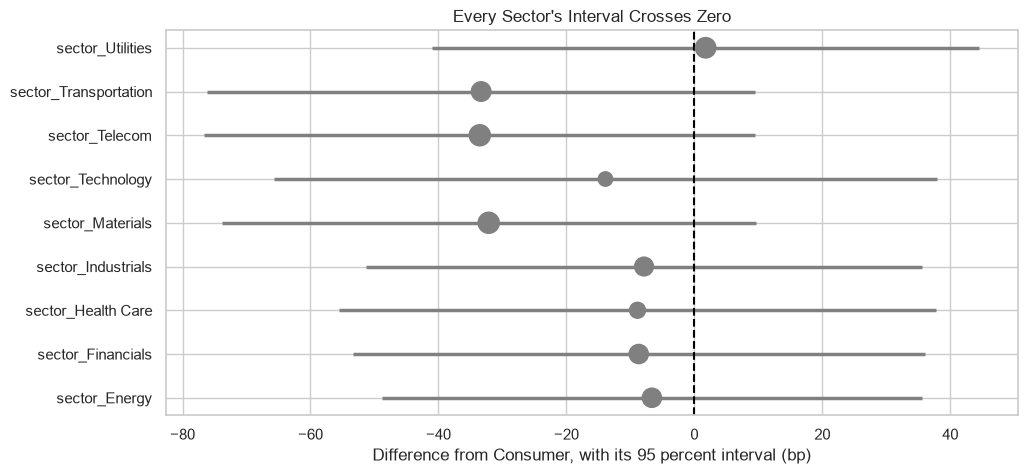

In [21]:
# the same forest plot, one row per sector, each dot sized by its training bonds
plt.figure(figsize=(11, 5))
draw_forest(sector_table, X_train[sector_dummies.columns].sum() * 3)
plt.xlabel("Difference from Consumer, with its 95 percent interval (bp)")
plt.title("Every Sector's Interval Crosses Zero")
plt.show()

The coefficients run from -33.5 to 1.8 bp, the p-values from 0.126 to 0.936, and every line crosses zero.

The generator never used sector (Day 2), so this is what a column with nothing in it looks like.

## Nine Tests at Once: the F-test

Q. Are all nine sector coefficients zero together?

Nine p-values answer nine questions, and the **F-test** answers this one.

`compare_f_test` tests a bigger model against the smaller model inside it.

In [22]:
# the sector model against Day 2's model: are all nine sector coefficients zero together?
f_value, f_p_value, extra_columns = sector_model.compare_f_test(ols_model)
print("F:", round(f_value, 2), " p-value:", round(f_p_value, 3), " columns tested:", int(extra_columns))

F: 0.82  p-value: 0.599  columns tested: 9


F 0.82, p-value 0.599: the model with sector cannot be told from the model without it.

## How Often Noise Looks Significant

**Predict 1**

A column of pure noise has nothing to do with spread.

`rng.standard_normal(615)` draws one: 615 numbers from a bell curve centred on zero.

Add one such column to Day 2's model, 1,000 times over, each fresh, and read its p-value from the fit's `.pvalues`.

How many of the 1,000 get a p-value below 0.05?

In [23]:
# 1,000 columns of pure noise, each added alone to Day 2's model; keep each one's p-value
rng = np.random.default_rng(SEED)
noise_p = []
for i in range(1000):
    noisy = X_train[features_steps].assign(noise=rng.standard_normal(len(X_train)))
    noise_p.append(sm.OLS(y_train, sm.add_constant(noisy)).fit().pvalues["noise"])
noise_p = np.array(noise_p)
print("Below 0.05:", (noise_p < 0.05).sum(), "of 1000.  Below 0.01:", (noise_p < 0.01).sum(), "of 1000.")

Below 0.05: 58 of 1000.  Below 0.01: 13 of 1000.


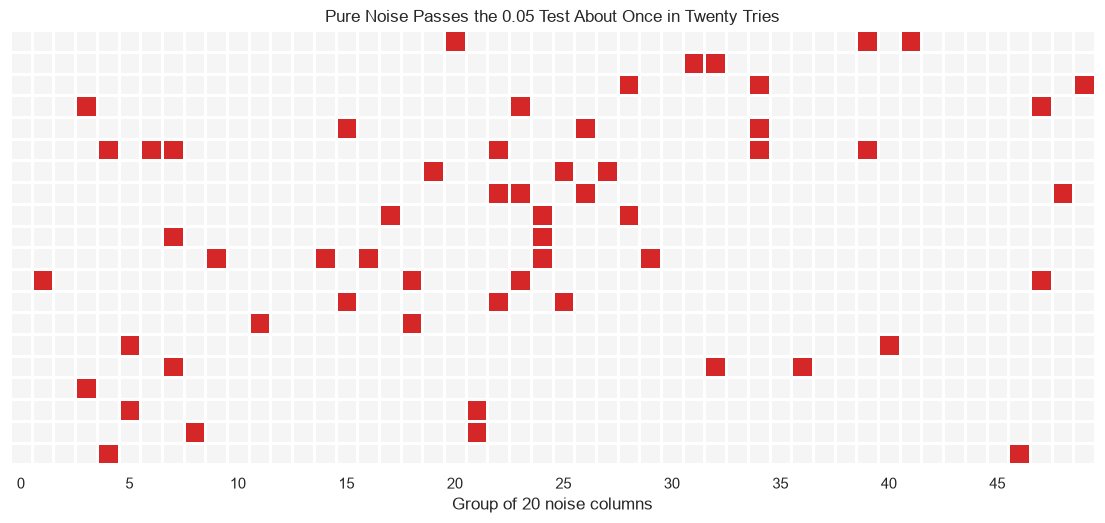

Groups of 20 with a 'significant' noise column: 36 of 50
Chance that at least one of 9 noise columns is below 0.05: 0.37


In [24]:
# a waffle chart: the 1,000 noise columns as 50 groups of 20, one group per column, red where p fell below 0.05
passed = (noise_p < 0.05).reshape(50, 20)
plt.figure(figsize=(14, 6))
sns.heatmap(passed.T, cmap=["whitesmoke", "tab:red"], cbar=False, linewidths=1, linecolor="white", square=True,
            xticklabels=5, yticklabels=False)
plt.xlabel("Group of 20 noise columns")
plt.title("Pure Noise Passes the 0.05 Test About Once in Twenty Tries")
plt.show()

# groups of 20 holding at least one noise column below 0.05, and the chance for a group of 9
print("Groups of 20 with a 'significant' noise column:", (passed.sum(axis=1) > 0).sum(), "of 50")
print("Chance that at least one of 9 noise columns is below 0.05:", round(1 - 0.95 ** 9, 2))

58 of 1,000 noise columns pass 0.05 and 13 pass 0.01: about one in twenty and one in a hundred, as the convention allows.

36 of the 50 groups of 20 hold at least one.

With nine noise columns, as many as the sectors, the chance that at least one falls below 0.05 is 37 percent.

So test a group together, as the F-test does, and never go fishing through columns for a small p-value.

**Sector stays out, now with a test behind it. Next, columns that are not noise but near-copies.**

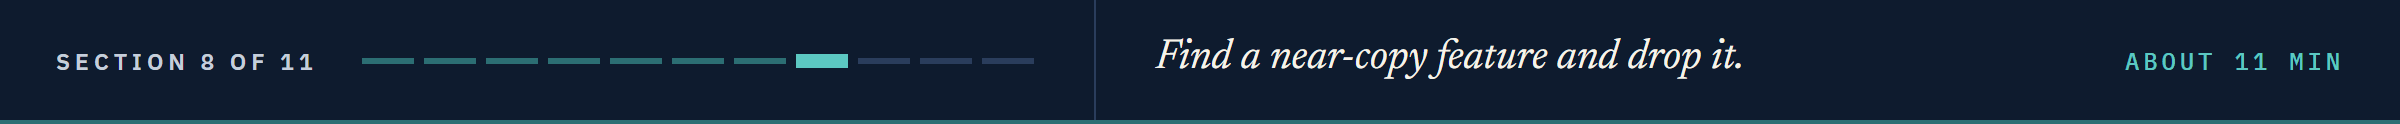

# Multicollinearity

## Adding Years to Maturity

**Predict 2**

Years to maturity joins duration in the model.

Duration's interval was -0.18 to 5.50 bp per year.

Sketch it on a line, then sketch where duration's interval lands with years beside it.

In [25]:
# Day 2's columns plus years to maturity
features_pair = features_steps + ["years_to_maturity"]
pair_model = sm.OLS(y_train, sm.add_constant(X_train[features_pair])).fit()
pair_table = pair_model.summary2().tables[1]
pair_table.loc[["duration", "years_to_maturity"]]

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
duration,-10.393,4.757,-2.185,0.029,-19.735,-1.051
years_to_maturity,6.435,2.235,2.879,0.004,2.045,10.825


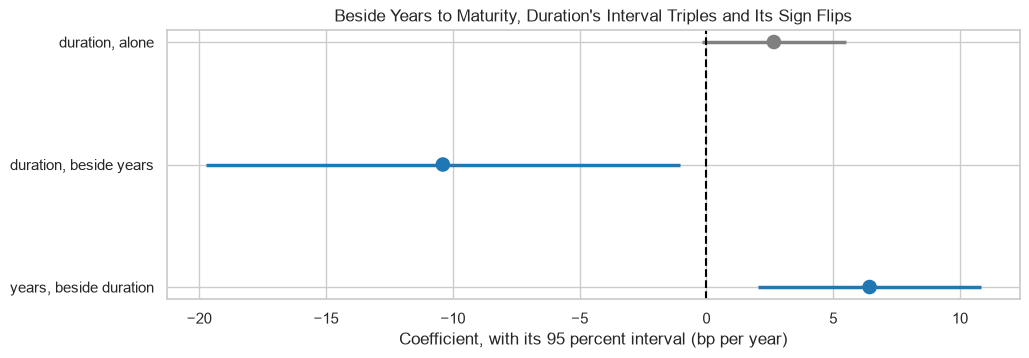

Interval width ratio: 3.29
R-squared: 0.6727 to 0.6772


In [26]:
# duration alone, duration beside years, and years beside duration, on one forest plot
three = pd.DataFrame([table.loc["duration"], pair_table.loc["duration"], pair_table.loc["years_to_maturity"]],
                     index=["duration, alone", "duration, beside years", "years, beside duration"]).iloc[::-1]
plt.figure(figsize=(11, 3.5))
draw_forest(three, 90)
plt.xlabel("Coefficient, with its 95 percent interval (bp per year)")
plt.title("Beside Years to Maturity, Duration's Interval Triples and Its Sign Flips")
plt.show()

# how many times wider duration's interval is with years beside it, and R-squared before and after
widths = three["0.975]"] - three["[0.025"]
print("Interval width ratio:", round(widths["duration, beside years"] / widths["duration, alone"], 2))
print("R-squared:", round(ols_model.rsquared, 4), "to", round(pair_model.rsquared, 4))

Beside years, duration's interval is 3.29 times wider and its coefficient flips to -10.39 bp per year.

R-squared barely moves, 0.6727 to 0.6772: the fit is no better, only the reading changed.

This is **multicollinearity**: two features so closely related that the fit cannot tell their effects apart.

### Interpretation: Association, Not Cause

Holding years fixed, more duration goes with less fitted spread.

At one maturity, a wider spread means a higher yield, and a higher yield means a shorter duration.

The file computes duration from the yield, so here the arrow runs from spread to duration.

No coefficient says what changing a column would do.

## Where the Data Cannot Choose

**Resampling**, also called the **bootstrap**, asks how much a coefficient moves on other bonds like these.

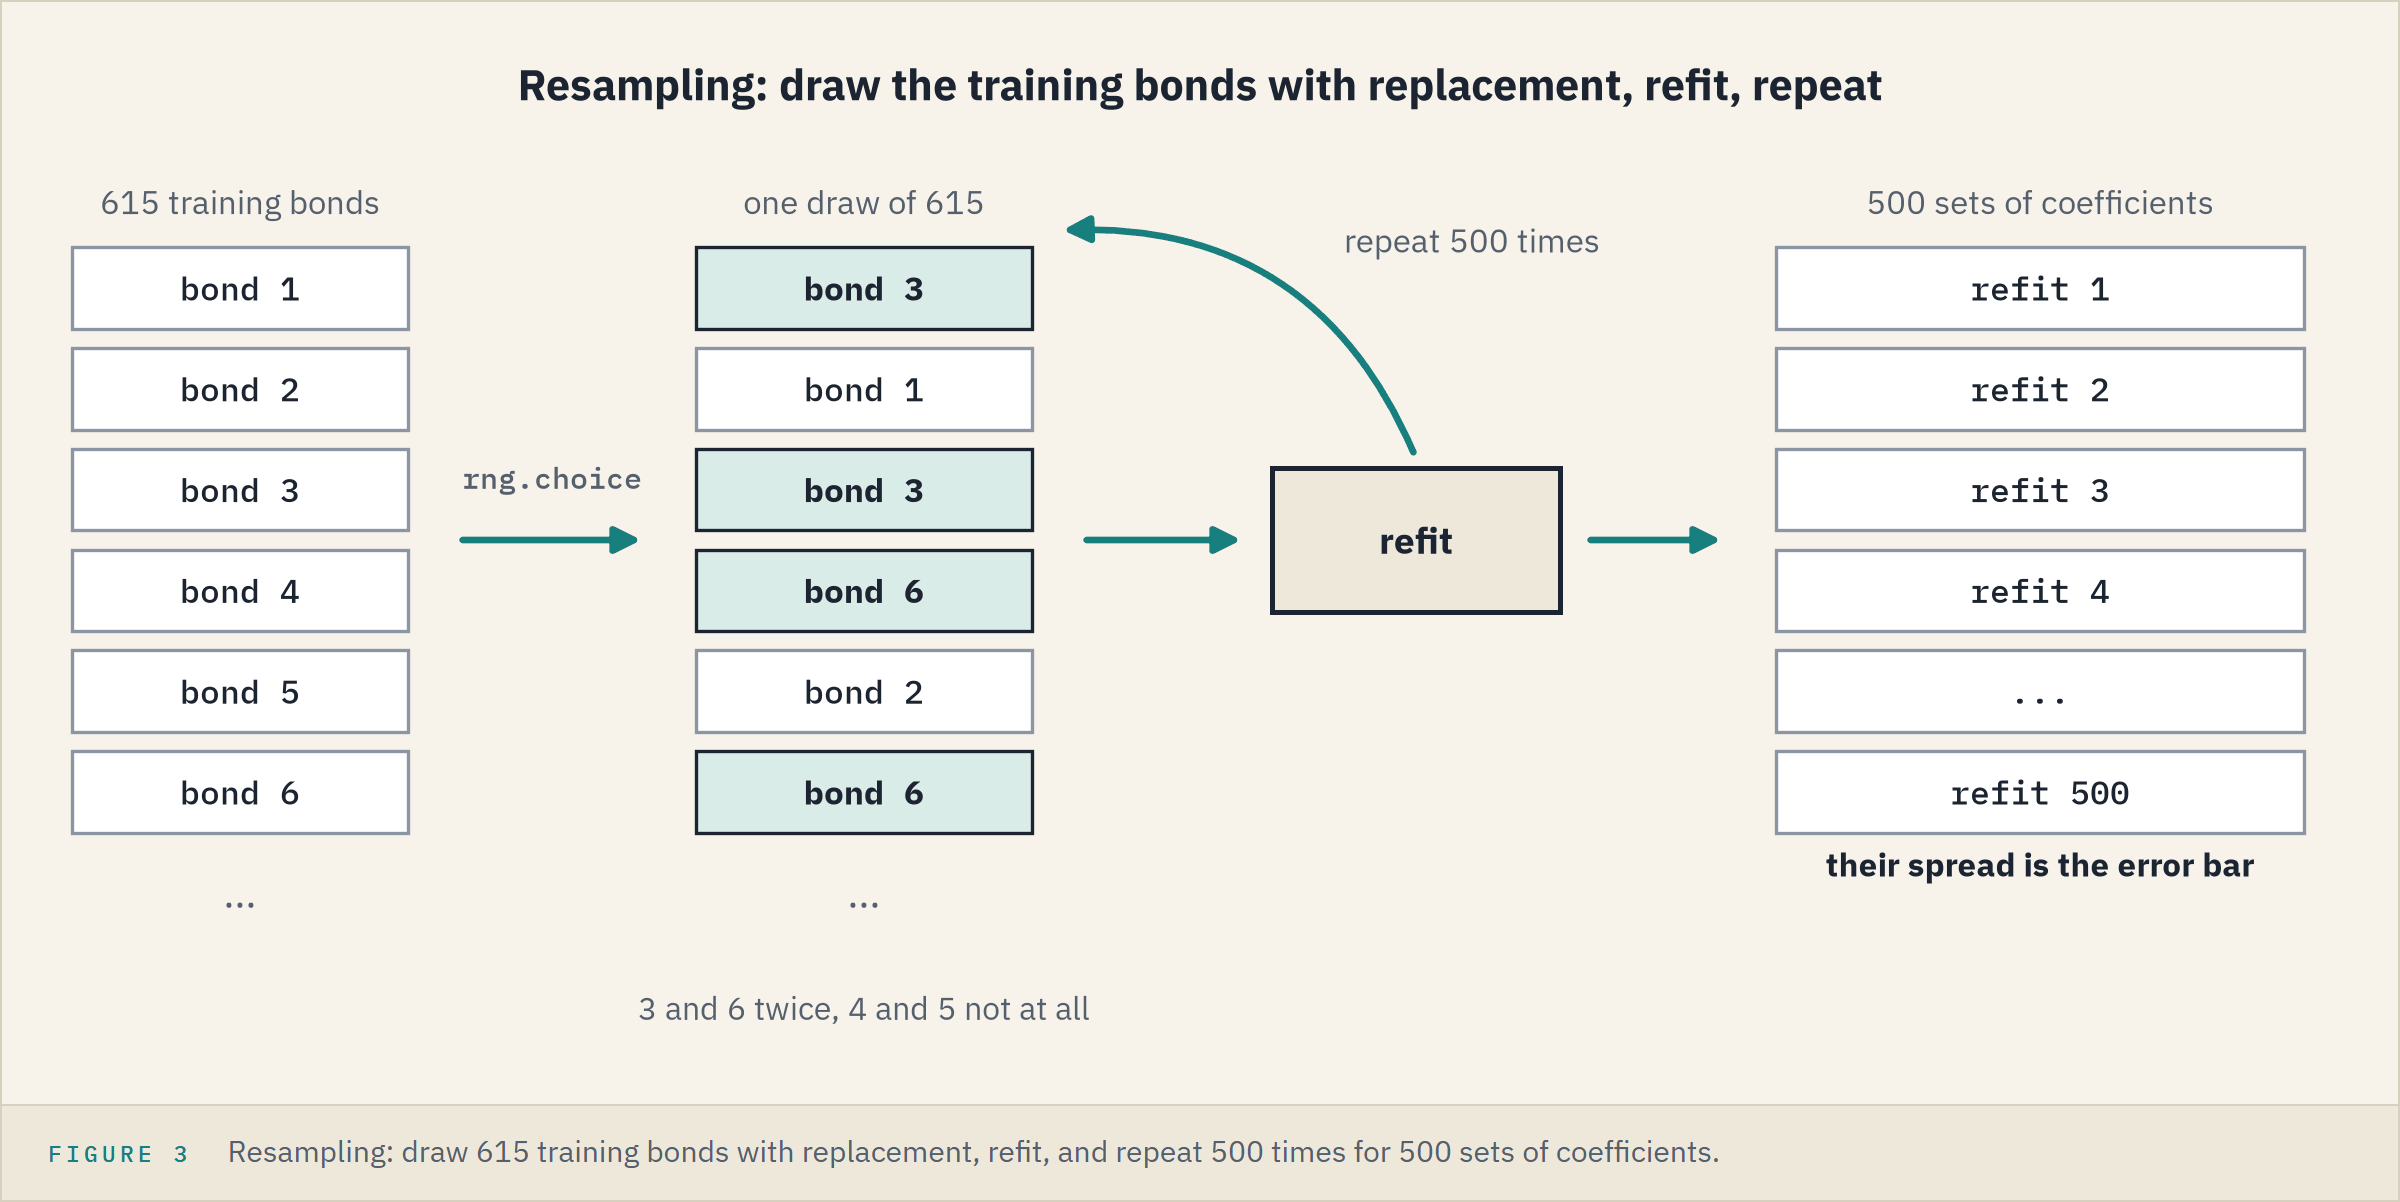

Draw 615 training bonds with replacement, refit, and repeat.

`rng.choice(615, size=615)` draws the row positions.

In [27]:
# draw 615 training bonds with replacement, refit, keep the coefficients; 500 times
def resampled_coefficients(features):
    rng = np.random.default_rng(SEED)
    rows = []
    for i in range(500):
        picks = rng.choice(len(X_train), size=len(X_train))
        refit = LinearRegression().fit(X_train[features].iloc[picks], y_train.iloc[picks])
        rows.append(refit.coef_)
    return pd.DataFrame(rows, columns=features)

**Predict 3**

Sketch the 500 refitted pairs: duration's coefficient across, years' up.

The chart then lays them over contour lines, which join pairs of coefficients with the same training RMSE, like height lines on a map.

`plt.contour` draws them and `plt.clabel` labels them.

`.fittedvalues` holds the model's fitted spreads for the training bonds.

In [28]:
# 500 refits of the model with both columns
pair_refits = resampled_coefficients(features_pair)

# training RMSE in bp over a grid of the two coefficients, every other coefficient held at its fitted value
b = pair_model.params
others = pair_model.fittedvalues - b["duration"] * X_train["duration"] - b["years_to_maturity"] * X_train["years_to_maturity"]
duration_grid, years_grid = np.meshgrid(np.linspace(-40, 10, 60), np.linspace(-6, 22, 60))
rmse_grid = np.zeros(duration_grid.shape)
for i in range(60):
    for j in range(60):
        fitted = others + duration_grid[i, j] * X_train["duration"] + years_grid[i, j] * X_train["years_to_maturity"]
        rmse_grid[i, j] = np.sqrt(((y_train - fitted) ** 2).mean())

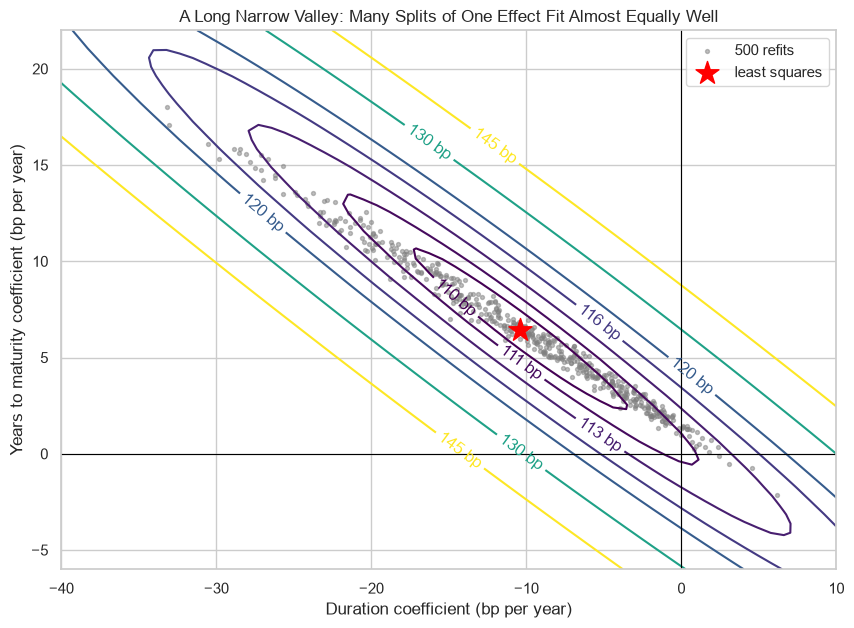

Correlation of the refitted pairs: -0.99


In [29]:
# the error surface as rings of equal RMSE, with the 500 refitted pairs and the least squares point on it
plt.figure(figsize=(10, 7))
rings = plt.contour(duration_grid, years_grid, rmse_grid, levels=[110, 111, 113, 116, 120, 130, 145], cmap="viridis")
plt.clabel(rings, fmt="%.0f bp")
plt.scatter(pair_refits["duration"], pair_refits["years_to_maturity"], s=8, color="gray", alpha=0.5, label="500 refits")
plt.scatter(b["duration"], b["years_to_maturity"], marker="*", s=300, color="red", label="least squares")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Duration coefficient (bp per year)")
plt.ylabel("Years to maturity coefficient (bp per year)")
plt.title("A Long Narrow Valley: Many Splits of One Effect Fit Almost Equally Well")
plt.legend()
plt.show()

# how closely the two refitted coefficients move together
print("Correlation of the refitted pairs:", round(pair_refits["duration"].corr(pair_refits["years_to_maturity"]), 2))

The rings make a long narrow valley, and the 500 refits lie along its floor, correlation -0.99.

More duration with less years fits almost as well as less duration with more years.

The data pins down a blend of the two, not each one alone, so each interval is wide while the fit is no better.

## Measuring It: the Variance Inflation Factor

Q. How closely does each column copy the others?

The **variance inflation factor** (VIF) measures it one column at a time: fit that column on all the other features, then take 1 / (1 - R-squared).

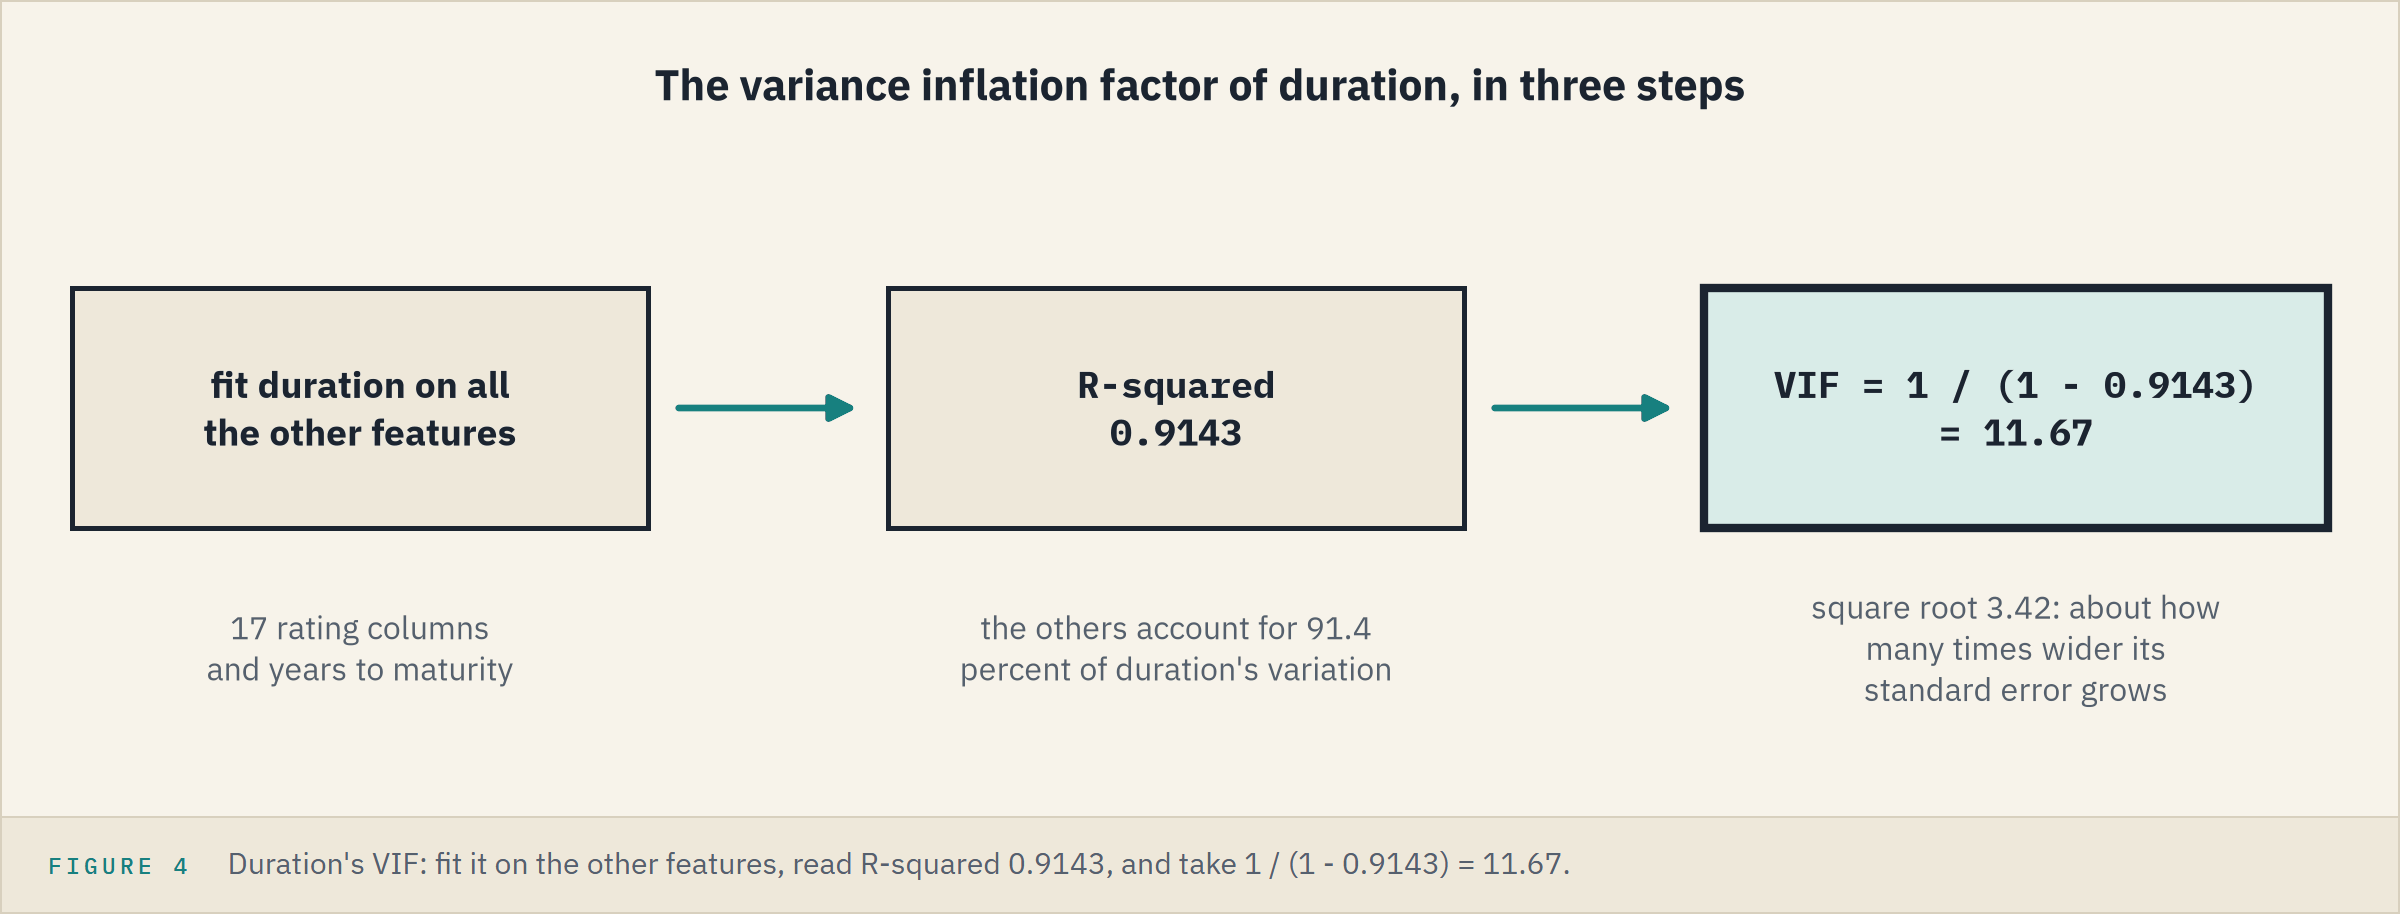

Its square root is roughly how many times wider the column's standard error grows.

Above 5 is high and above 10 very high, by convention.

`variance_inflation_factor(design, i)` does it for column `i`, with the constant in the design.

In [30]:
# each column's VIF, with the constant in the design; the constant's own row dropped
design = sm.add_constant(X_train[features_pair])
vif = pd.Series([variance_inflation_factor(design.values, i) for i in range(len(design.columns))], index=design.columns)
vif = vif.drop("const")
vif.sort_values(ascending=False).head(4)

duration            11.666
years_to_maturity   11.437
rating_A-            2.079
rating_BBB-          2.059
dtype: float64

Duration 11.67 and years 11.44, both above 10; the next column, A-, sits at 2.08.

## An Exact Copy: Spread Duration

Spread duration equals duration on every bond, so it is the extreme case.

In [31]:
# spread duration beside duration, fitted with scikit-learn
copy_model = LinearRegression()
copy_model.fit(X_train[features_steps + ["spread_duration"]], y_train)
print("Duration:", round(copy_model.coef_[-2], 2), " Spread duration:", round(copy_model.coef_[-1], 2))

Duration: 1.33  Spread duration: 1.33


In [32]:
# hand any share of Day 2's 2.66 bp per year to duration and the rest to spread duration: training RMSE for each share
b_duration = ols_model.params["duration"]
without_duration = ols_model.fittedvalues - b_duration * X_train["duration"]
shares = np.linspace(-1, 2, 31)
rmse_by_share = []
for share in shares:
    fitted = without_duration + share * b_duration * X_train["duration"] + (1 - share) * b_duration * X_train["spread_duration"]
    rmse_by_share.append(np.sqrt(((y_train - fitted) ** 2).mean()))
print("Training RMSE from", round(min(rmse_by_share), 2), "to", round(max(rmse_by_share), 2), "bp")

Training RMSE from 110.18 to 110.18 bp


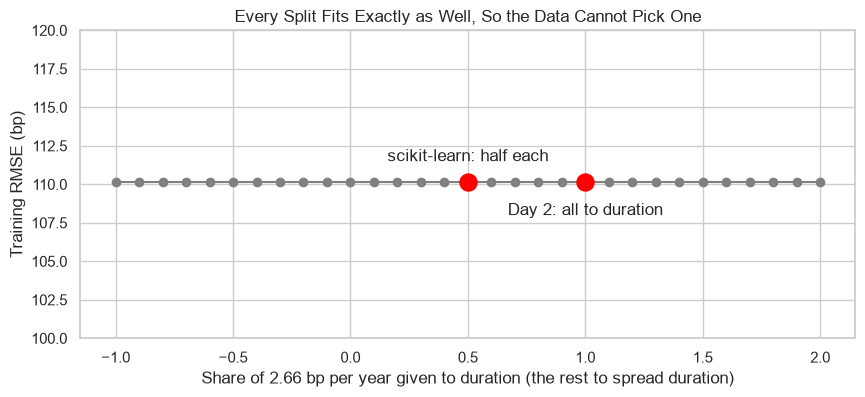

In [33]:
# training RMSE against the share, with scikit-learn's half-and-half and Day 2's all-to-duration marked
plt.figure(figsize=(10, 4))
plt.plot(shares, rmse_by_share, marker="o", color="gray")
plt.scatter([0.5, 1.0], [rmse_by_share[15], rmse_by_share[20]], s=150, color="red", zorder=3)
plt.text(0.5, 111.5, "scikit-learn: half each", ha="center")
plt.text(1.0, 108, "Day 2: all to duration", ha="center")
plt.ylim(100, 120)
plt.xlabel("Share of 2.66 bp per year given to duration (the rest to spread duration)")
plt.ylabel("Training RMSE (bp)")
plt.title("Every Split Fits Exactly as Well, So the Data Cannot Pick One")
plt.show()

scikit-learn splits Day 2's 2.66 into 1.33 and 1.33, and every other split fits exactly as well, 110.18 bp.

Spread duration fitted on the other features has R-squared 1, so its VIF is 1 / 0: infinite.

**An exact copy adds nothing and gives no answer, so it never enters a model.**

## Dropping a Feature by VIF

The usual method: drop each high-VIF column in turn, and keep the model that loses the least adjusted R-squared.

In [34]:
# years to maturity in place of duration
features_final = list(rating_dummies.columns) + ["years_to_maturity"]
final_model = sm.OLS(y_train, sm.add_constant(X_train[features_final])).fit()

# adjusted R-squared with each of the pair dropped, then with both kept
print("Drop years, keep duration:", round(ols_model.rsquared_adj, 4))
print("Drop duration, keep years:", round(final_model.rsquared_adj, 4))
print("Keep both:                ", round(pair_model.rsquared_adj, 4))

Drop years, keep duration: 0.6628
Drop duration, keep years: 0.6648
Keep both:                 0.6669


**Dropping duration costs least, so duration goes and years to maturity stays.**

In [35]:
# every VIF again, without duration
design_final = sm.add_constant(X_train[features_final])
vif_final = pd.Series([variance_inflation_factor(design_final.values, i) for i in range(len(design_final.columns))],
                      index=design_final.columns).drop("const")
print("Years to maturity now:", round(vif_final["years_to_maturity"], 2), " Largest:", round(vif_final.max(), 2))

Years to maturity now: 1.05  Largest: 2.08


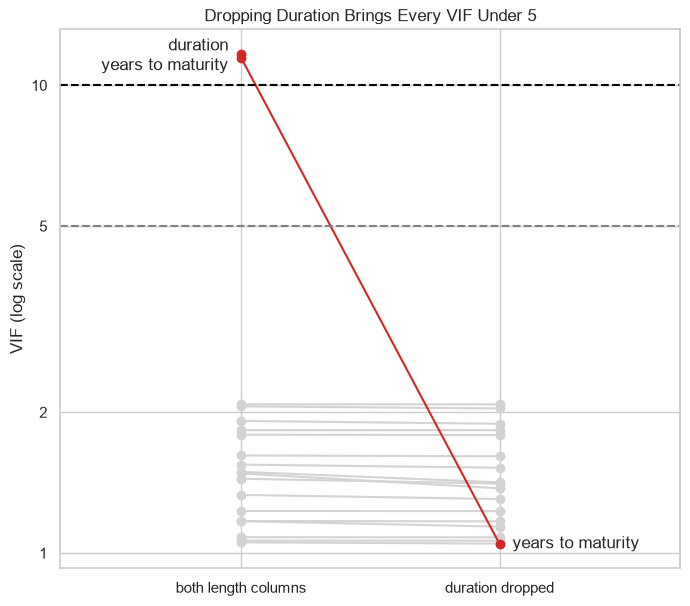

In [36]:
# a slope chart: each column's VIF with both length columns (left) and after dropping duration (right)
plt.figure(figsize=(8, 7))
for name in vif.index:
    colour = "tab:red" if name in ["duration", "years_to_maturity"] else "lightgray"
    # .get gives NaN for duration, which has no point on the right
    plt.plot([0, 1], [vif[name], vif_final.get(name, np.nan)], marker="o", color=colour)
plt.text(-0.05, vif["duration"], "duration", ha="right", va="bottom")
plt.text(-0.05, vif["years_to_maturity"], "years to maturity", ha="right", va="top")
plt.text(1.05, vif_final["years_to_maturity"], "years to maturity", ha="left", va="center")
plt.axhline(5, color="gray", linestyle="--")
plt.axhline(10, color="black", linestyle="--")
plt.yscale("log")
plt.yticks([1, 2, 5, 10], ["1", "2", "5", "10"])
plt.xticks([0, 1], ["both length columns", "duration dropped"])
plt.xlim(-0.7, 1.7)
plt.ylabel("VIF (log scale)")
plt.title("Dropping Duration Brings Every VIF Under 5")
plt.show()

Years to maturity falls from 11.44 to 1.05, and no column is left above 2.08.

The generator builds every spread from years to maturity, capped at 10, and never from duration: VIF chose the generator's own column.

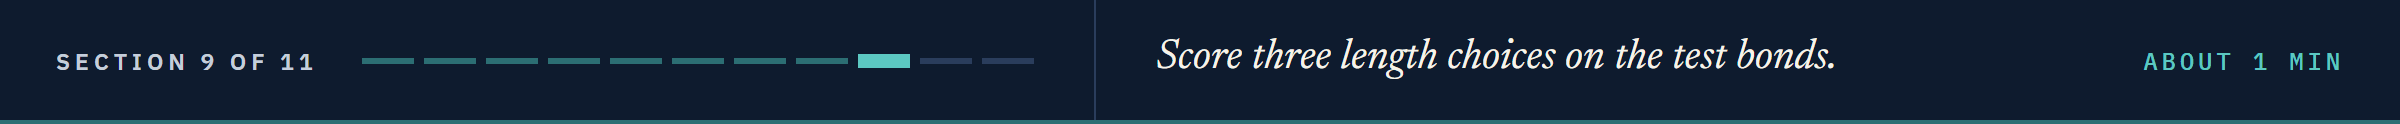

# Model Performance Evaluation

## Scoring the Three Models on the Test Bonds

Q. Does a near-copy change the miss on unseen bonds?

statsmodels' `.predict` needs the same `const` column, so the test bonds get `sm.add_constant` too.

In [37]:
# each model's fitted spreads for the test bonds, then MAE, RMSE and R-squared
scores = {}
for name, model, features in [("Duration", ols_model, features_steps), ("Both", pair_model, features_pair),
                              ("Years to maturity", final_model, features_final)]:
    fitted = model.predict(sm.add_constant(X_test[features]))
    scores[name] = {"MAE (bp)": mean_absolute_error(y_test, fitted), "RMSE (bp)": np.sqrt(mean_squared_error(y_test, fitted)),
                    "R-squared": r2_score(y_test, fitted)}
pd.DataFrame(scores)

,Duration,Both,Years to maturity
MAE (bp),35.539,36.523,35.445
RMSE (bp),69.135,68.839,68.812
R-squared,0.818,0.819,0.820


The three test MAEs sit within 1.1 bp: 35.5, 36.5 and 35.4 bp.

A near-copy spoils the reading of the coefficients, and hardly touches the fitted spreads.

**We keep the rating steps and years to maturity: the same fit, and a length coefficient that can be read.**

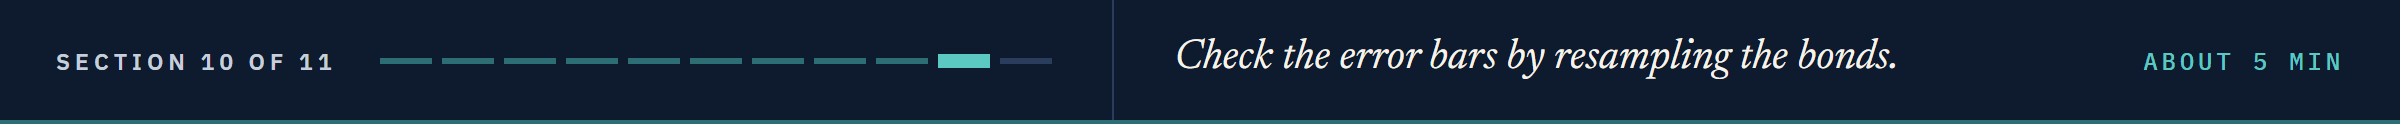

# When the Error Bars Are Wrong

## Resampled Error Bars Against `statsmodels`

**Predict 4**

In the kept model, statsmodels gives AAA's step a standard error of 36.7 bp (a fit keeps its standard errors in `.bse`).

Resampling measures the same thing a second way.

Write down the standard deviation of AAA's step across 500 refits, in bp.

In [38]:
# 500 refits of the kept model, and five levels' spread across them beside statsmodels' standard errors, in bp
refits = resampled_coefficients(features_final)
levels = ["rating_AAA", "rating_BBB", "rating_BB", "rating_B", "rating_CCC+"]
pd.DataFrame({"statsmodels' standard error": final_model.bse[levels], "spread of 500 refits": refits[levels].std()})

,statsmodels' standard error,spread of 500 refits
rating_AAA,36.699,5.591
rating_BBB,22.633,6.030
rating_BB,23.959,10.867
rating_B,25.683,73.399
rating_CCC+,39.980,107.579


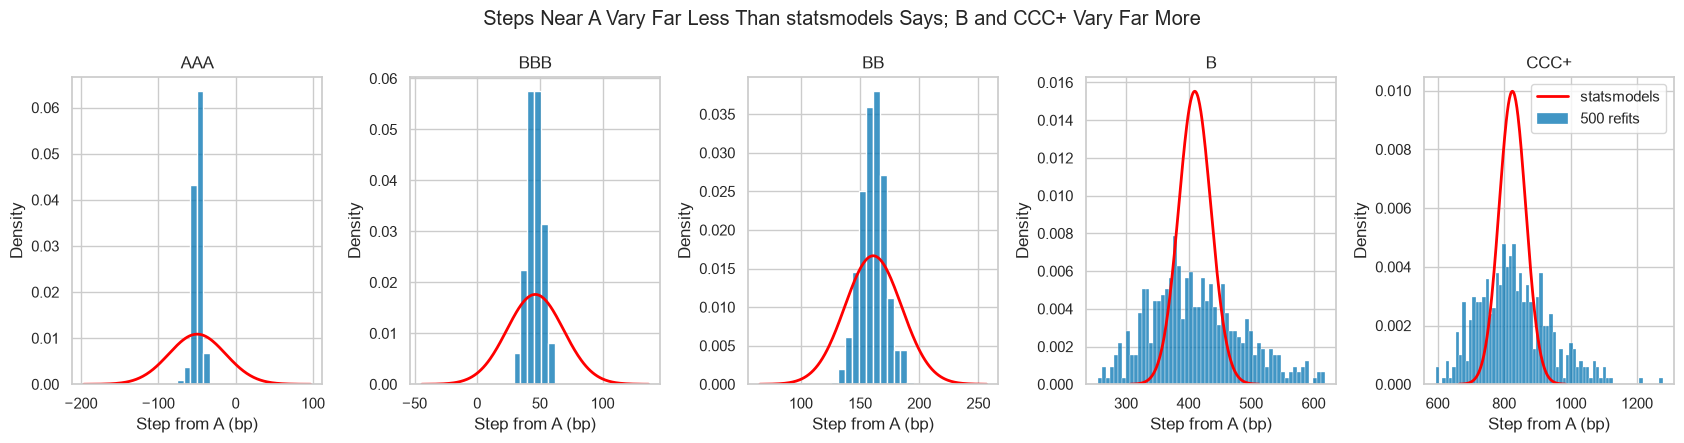

In [39]:
# small multiples: each level's 500 refitted steps as bars
# stats.norm.pdf(grid, centre, error) draws statsmodels' bell curve, in red, at that centre and standard error
fig, axes = plt.subplots(1, 5, figsize=(17, 4.5))
for ax, level in zip(axes, levels):
    centre, error = final_model.params[level], final_model.bse[level]
    grid = np.linspace(centre - 4 * error, centre + 4 * error, 200)
    sns.histplot(refits[level], stat="density", binwidth=error / 4, ax=ax, label="500 refits")
    ax.plot(grid, stats.norm.pdf(grid, centre, error), color="red", linewidth=2, label="statsmodels")
    ax.set_title(level.replace("rating_", ""))
    ax.set_xlabel("Step from A (bp)")
axes[4].legend(loc="upper right")
fig.suptitle("Steps Near A Vary Far Less Than statsmodels Says; B and CCC+ Vary Far More")
fig.tight_layout()
plt.show()

Investment grade steps vary far less across refits than statsmodels says: AAA 5.59 bp against 36.70, BBB 6.03 against 22.63.

BB, 10.87 against 23.96, still varies less.

The steps deep in high yield vary far more: B 73.40 against 25.68, CCC+ 107.58 against 39.98.

### Why They Disagree

`.resid` holds the training misses, and `.scale` is the square of the one noise size statsmodels assumes for every bond.

In [40]:
# the one noise size statsmodels gives every bond, in bp
print("statsmodels' noise size:", round(np.sqrt(final_model.scale), 1))

# the training misses' standard deviation within each grade, in bp
final_model.resid.groupby(data.loc[X_train.index, "grade"]).std()

statsmodels' noise size: 111.6


grade
High Yield         184.774
Investment Grade    25.019
dtype: float64

statsmodels gives every bond one noise size, 111.6 bp.

The real misses run 25.0 bp for investment grade and 184.8 bp for high yield: Day 2's fan.

So the error bars on steps near A come out too wide, and those deep in high yield too narrow.

**An error bar assumes one noise size for every bond. Day 4 tests that assumption and takes logs.**

## Bonds of One Issuer Miss Together

A second assumption: each bond's miss is independent of every other bond's.

The generator gives every issuer its own effect (Day 2), so an issuer's bonds should miss together.

The test: replace each miss with its issuer's average miss and see what share of the squared misses survives, then shuffle the issuer labels and do it again.

`rng.permutation` returns the labels in a random order.

In [41]:
# investment grade training bonds: each one's miss under the kept model, its issuer, and the issuers shuffled once
ig = data.loc[X_train.index, "grade"] == "Investment Grade"
misses = pd.DataFrame({"miss": final_model.resid[ig], "issuer": data.loc[X_train.index, "ticker"][ig]})
rng = np.random.default_rng(SEED)
misses["shuffled"] = rng.permutation(misses["issuer"].to_numpy())
print(len(misses), "bonds from", misses["issuer"].nunique(), "issuers")

# the share of the squared misses that issuer averages keep, real labels then shuffled
for labels in ["issuer", "shuffled"]:
    average = misses.groupby(labels)["miss"].transform("mean")
    print(labels, round((average ** 2).sum() / (misses["miss"] ** 2).sum() * 100, 1), "percent")

404 bonds from 98 issuers
issuer 47.2 percent
shuffled 25.0 percent


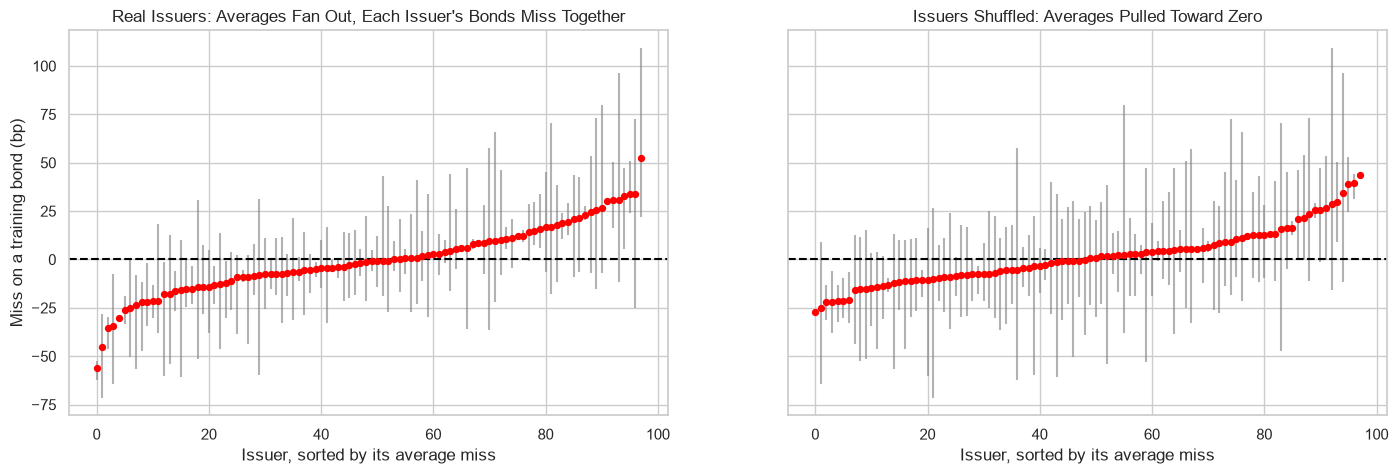

In [42]:
# a caterpillar plot: one column per issuer, sorted by its average miss, a line from its lowest miss to its highest
fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=True)
for ax, labels in zip(axes, ["issuer", "shuffled"]):
    issuer_misses = misses.groupby(labels)["miss"].agg(["mean", "min", "max"]).sort_values("mean")
    ax.vlines(range(len(issuer_misses)), issuer_misses["min"], issuer_misses["max"], color="gray", alpha=0.6)
    ax.scatter(range(len(issuer_misses)), issuer_misses["mean"], s=18, color="red", zorder=3)
    ax.axhline(0, color="black", linestyle="--")
    ax.set_xlabel("Issuer, sorted by its average miss")
axes[0].set_ylabel("Miss on a training bond (bp)")
axes[0].set_title("Real Issuers: Averages Fan Out, Each Issuer's Bonds Miss Together")
axes[1].set_title("Issuers Shuffled: Averages Pulled Toward Zero")
plt.show()

Issuer averages keep 47.2 percent of the squared misses with real issuers and 25.0 percent with shuffled labels.

So 404 bonds from 98 issuers are fewer than 404 independent pieces of evidence, and the error bars come out too narrow.

Error bars that allow for this, clustered by issuer, are a later topic.

**Two assumptions sit under every error bar, one noise size and independent bonds, and this file breaks both.**

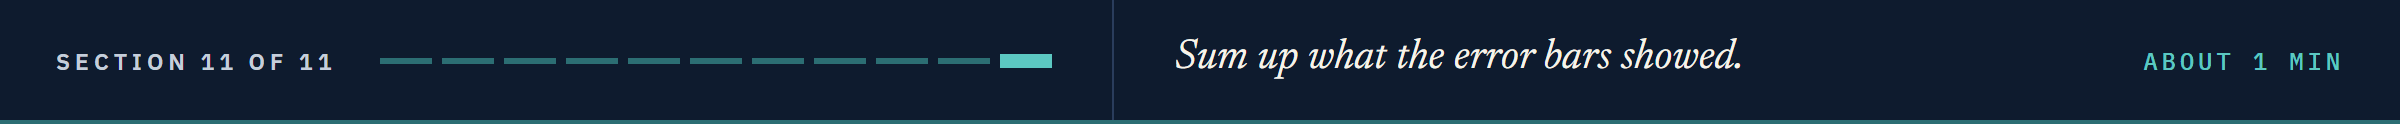

# Insights and Conclusion

Read the error bar before the number: high yield steps stand clear of zero, and the steps beside A cannot be told from zero in bp.

Sector's nine p-values and its F-test agree there is nothing there, as the generator says.

Pure noise passes 0.05 about once in twenty, so test groups together and never go fishing.

A near-copy flipped a sign and tripled an interval while the test MAE hardly moved, and VIF chose years to maturity, the generator's own column.

An error bar is only as good as its assumptions, and in bp this file breaks two.

**Day 4 checks those assumptions one by one.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit a regression with statsmodels and read its standard errors, t values, p-values and 95 percent intervals.
* Draw a p-value as two tails of the t distribution, and coefficients as a forest plot.
* Test a group of columns together with an F-test, and say why fishing finds noise.
* Find a near-copy feature with VIF and drop it by adjusted R-squared.
* Check error bars by resampling, and name the two assumptions under them.

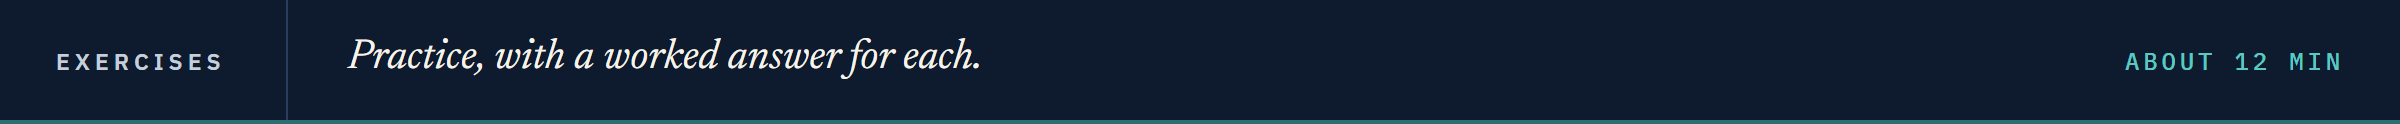

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [43]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Coupon Beside the Rating Steps**

Q. Add `coupon` to the kept model's columns (the rating steps and years to maturity) for the training bonds.
Compute every VIF as the notebook does, and store coupon's in `ex1_vif`.

In [44]:
# your code here
ex1_vif = ...

In [45]:
check("Exercise 1 coupon's VIF", ex1_vif, 2.5672390346399334)

Exercise 1 coupon's VIF: not attempted yet


### Exercise 2

**The Kept Model's Years Coefficient**

Q. From `final_model`'s coefficient table, store the 95 percent interval of the years to maturity coefficient, in bp per year, in `ex2_low` and `ex2_high`.

In [46]:
# your code here
ex2_low = ...
ex2_high = ...

In [47]:
check("Exercise 2 the low end", ex2_low, 0.4485603848545292)
check("Exercise 2 the high end", ex2_high, 3.1111450963040723)

Exercise 2 the low end: not attempted yet
Exercise 2 the high end: not attempted yet


### Exercise 3

**The Names Below a Level**

Q. Write `significant(table, level)`: it returns a list of the names in a coefficient table whose `P>|t|` is below `level`.
Use it on `final_model`'s coefficient table at 0.05 and store the list in `ex3_names`.

In [48]:
# your code here
ex3_names = ...

In [49]:
check("Exercise 3 the names below 0.05", ex3_names, ['const', 'rating_BBB', 'rating_BBB-', 'rating_BB+', 'rating_BB', 'rating_BB-', 'rating_B+', 'rating_B', 'rating_B-', 'rating_CCC+', 'rating_CCC', 'years_to_maturity'])

Exercise 3 the names below 0.05: not attempted yet


### Exercise 4: AI check

**More Information, a Better Model**

You asked an AI assistant to improve the kept model.

This came back.

It runs, and it reports a smaller test miss.

`.tvalues` holds each column's t.

In [50]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def spread_model_with_more_information(features):
    # the kept model's columns plus DTS, for more information about each bond
    with_dts = X[features].assign(dts=data["dts"])
    model = sm.OLS(y_train, sm.add_constant(with_dts.loc[X_train.index])).fit()
    fitted = model.predict(sm.add_constant(with_dts.loc[X_test.index]))
    return model, mean_absolute_error(y_test, fitted)

model_dts, test_mae = spread_model_with_more_information(features_final)
print("Most significant column:", model_dts.pvalues.idxmin(), " t:", round(model_dts.tvalues["dts"], 1))
print("Test MAE:", round(test_mae, 1), "bp")

Most significant column: dts  t: 30.3
Test MAE: 30.0 bp


Q. What is `dts` made of?
Fix the model and store its test MAE in bp in `ex4_test_mae_bp`.

In [51]:
# your code here
ex4_test_mae_bp = ...

In [52]:
check("Exercise 4 the fixed test MAE", ex4_test_mae_bp, 35.44452972807877)

Exercise 4 the fixed test MAE: not attempted yet


## Congratulations!

You put an error bar on every coefficient today and learned to read it before the number.
You watched 58 noise columns in 1,000 pass a significance test, and an F-test settle sector in one line.
You caught a near-copy flipping duration's sign, measured it with VIF, and dropped it without losing a bp on unseen bonds.
Then you resampled the bonds and found statsmodels' error bars too wide near A and too narrow deep in high yield.
On Day 4 you test the assumptions behind them and take logs.

[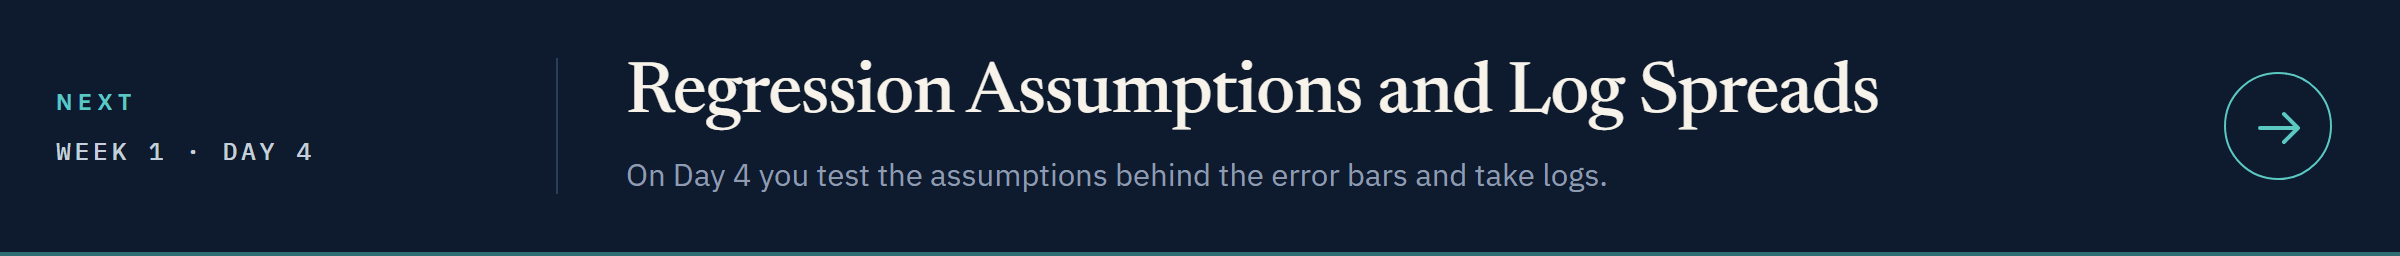](../day4/04_regression_assumptions_and_log_spreads.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week1/day4/04_regression_assumptions_and_log_spreads.ipynb)